<a href="https://colab.research.google.com/github/arielsharonferdinandus/Telco_Customer_Churn_Prediction/blob/Modeling-comparison-and-optimization/Telco_Churn_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction (PA-1A)

**Dataset:** Telco Customer Churn (IBM, via Kaggle) — `1A_telco_customer_churn.csv`
**Sumber:** https://github.com/arielsharonferdinandus/Telco_Customer_Churn_Prediction/blob/main/data/1A_telco_customer_churn.csv

Notebook ini disusun bertahap per *phase*:

| Phase | Isi |
|---|---|
| **1** | Task 1 — Business Understanding, Data Quality Check, EDA |
| 2 | Task 2 — Data Preparation & Feature Engineering |
| 3 | Task 3 — Modeling, Comparison & Optimization |
| 4 | Task 4 — Evaluation, Interpretation & Business Recommendation |

In [100]:
import warnings, os, urllib.request
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42          # dipakai konsisten di seluruh notebook
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False})
COL = {'No': '#4C78A8', 'Yes': '#E4572E'}   # warna konsisten: No = biru, Yes (churn) = oranye-merah

---
# TASK 1 — Business Understanding & Data Diagnosis

## 1.1 Business Understanding

### Latar belakang
Industri telekomunikasi sangat kompetitif dan pelanggan mudah berpindah operator. Mendapatkan pelanggan baru umumnya jauh lebih mahal daripada mempertahankan pelanggan yang sudah ada, sehingga **churn** (pelanggan berhenti berlangganan) langsung menggerus pendapatan berulang. Pada dataset ini sekitar **26,5%** pelanggan churn — lebih dari satu dari empat pelanggan. Tim retensi memiliki sumber daya terbatas (anggaran, jumlah agen, penawaran diskon), sehingga tidak mungkin menghubungi semua pelanggan.

### Problem statement
Perusahaan telekomunikasi kehilangan sekitar 26,5% pelanggannya akibat churn, namun program retensi hanya dapat menjangkau sebagian kecil pelanggan karena keterbatasan anggaran dan kapasitas tim, sehingga tanpa kemampuan memprediksi siapa yang berisiko tinggi, upaya retensi cenderung dilakukan secara acak dan tidak efisien. Proyek ini membangun model klasifikasi biner yang memprediksi kemungkinan churn setiap pelanggan berdasarkan profil demografi, layanan yang digunakan, kontrak, dan pola penagihan, lalu mengurutkan pelanggan berdasarkan risiko agar tim retensi memprioritaskan pelanggan yang paling mungkin churn dan paling bernilai untuk dipertahankan.

### Tujuan penggunaan Machine Learning
1. **Memprioritaskan** pelanggan berisiko tinggi (ranking berbasis probabilitas churn) untuk program retensi.
2. **Meningkatkan efisiensi biaya** — jumlah pelanggan yang dihubungi sama, tetapi proporsi yang benar-benar akan churn (precision) lebih tinggi dibanding pemilihan acak.
3. **Mengidentifikasi pendorong churn** (kontrak, layanan, pembayaran, dll.) sebagai dasar desain program retensi.

### Target prediksi dan definisi kelas
| Kelas | Nilai `Churn` | Label model | Arti |
|---|---|---|---|
| Positif | `Yes` | 1 | Pelanggan berhenti berlangganan |
| Negatif | `No` | 0 | Pelanggan tetap berlangganan |

Masalah: **binary classification** dengan kelas positif (churn) sebagai minoritas (~26,5%).

### Metrik evaluasi model dan alasan pemilihan
| Metrik | Alasan pemilihan berdasarkan tujuan bisnis |
|---|---|
| **ROC-AUC** | Mengukur kemampuan model *meranking* pelanggan churn di atas non-churn pada semua threshold. Cocok karena output model dipakai sebagai skor prioritas, dan tidak bergantung pada satu threshold. |
| **PR-AUC** | Lebih sensitif terhadap kelas minoritas dibanding ROC-AUC saat data tidak seimbang. Baseline PR-AUC ≈ proporsi churn (0,265), sehingga mudah melihat nilai tambah model. |
| **Precision** | Dari pelanggan yang dihubungi, berapa persen benar-benar akan churn. Precision rendah = biaya retensi terbuang ke pelanggan yang sebenarnya akan tetap bertahan (dan diskon yang tidak perlu). |
| **Recall** | Dari seluruh pelanggan churn, berapa persen berhasil ditangkap. Recall rendah = banyak pendapatan hilang tanpa sempat ditangani. |
| **F1-Score** | Rata-rata harmonik precision dan recall; ringkasan tunggal untuk keseimbangan keduanya pada threshold tertentu. |
| **Confusion Matrix** | Menunjukkan jumlah TP, FP, FN, TN sehingga kesalahan dapat diterjemahkan langsung ke biaya (FP = biaya kampanye terbuang; FN = pelanggan churn terlewat). |

> **Catatan:** *Accuracy* tidak dijadikan metrik utama. Model yang selalu menebak "tidak churn" sudah mencapai akurasi ≈ 73,5% tanpa menangkap satu pun pelanggan churn.

### Metrik bisnis keberhasilan program retensi
| Metrik bisnis | Definisi | Alasan |
|---|---|---|
| **Churn rate** | Churn / total pelanggan | Indikator utama kesehatan basis pelanggan; target program adalah menurunkannya. |
| **Retention rate** | 1 − churn rate | Sisi positif dari churn rate; mudah dikomunikasikan ke manajemen. |
| **Expected saved revenue** | Pelanggan berhasil dipertahankan × MonthlyCharges × periode proyeksi | Menerjemahkan hasil model menjadi rupiah/dolar yang diselamatkan. |
| **Retention campaign conversion rate** | % pelanggan yang dikontak dan akhirnya bertahan | Mengukur efektivitas aksi retensi (diasumsikan, bukan diprediksi model). |
| **Lift @ top-k%** | Churn rate pada k% skor tertinggi ÷ churn rate keseluruhan | Mengukur seberapa lebih baik model dibanding pemilihan acak, sesuai kapasitas tim retensi (mis. top 10%/20%). |

## 1.2 Data Quality Check
Memuat data, lalu memeriksa tujuh aspek: missing values, duplikasi, tipe data, outlier, class imbalance, nilai tidak konsisten/tidak valid, serta distribusi kategori.

In [101]:
# Muat data dari folder lokal; jika belum ada, unduh dari GitHub (sumber yang ditentukan)
DATA_PATH = 'data/1A_telco_customer_churn.csv'
GITHUB_RAW = 'https://raw.githubusercontent.com/arielsharonferdinandus/Telco_Customer_Churn_Prediction/main/data/1A_telco_customer_churn.csv'
if not os.path.exists(DATA_PATH):
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve(GITHUB_RAW, DATA_PATH)

df_raw = pd.read_csv(DATA_PATH)
print('Shape:', df_raw.shape)
df_raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [102]:
# 1) Missing values (NaN) & 3) tipe data
info = pd.DataFrame({'dtype': df_raw.dtypes.astype(str), 'n_missing': df_raw.isna().sum(), 'n_unique': df_raw.nunique()})
info

,dtype,n_missing,n_unique
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


In [103]:
# 2) Duplikasi
print('Baris duplikat penuh      :', df_raw.duplicated().sum())
print('customerID duplikat       :', df_raw['customerID'].duplicated().sum())

# 3) / 6) TotalCharges bertipe string -> cari nilai yang tidak bisa dikonversi ke angka
tc_num = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')
bad = df_raw[tc_num.isna()]
print('\nTotalCharges tidak numerik:', len(bad), 'baris; nilai asli unik =', bad['TotalCharges'].map(repr).unique())
bad[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Baris duplikat penuh      : 0
customerID duplikat       : 0

TotalCharges tidak numerik: 11 baris; nilai asli unik = ["' '"]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [104]:
# 6) Konsistensi logika antar kolom
chk = {}
chk['tenure = 0 (pelanggan baru)']                     = int((df_raw.tenure == 0).sum())
chk['tenure = 0 dan TotalCharges kosong']              = int(((df_raw.tenure == 0) & tc_num.isna()).sum())
chk['PhoneService=No tapi MultipleLines != "No phone service"'] = int(((df_raw.PhoneService == 'No') & (df_raw.MultipleLines != 'No phone service')).sum())
net_cols = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
chk['InternetService=No tapi layanan internet != "No internet service"'] = int(((df_raw.InternetService == 'No') & (df_raw[net_cols] != 'No internet service').any(axis=1)).sum())
chk['MonthlyCharges <= 0'] = int((df_raw.MonthlyCharges <= 0).sum())
chk['tenure < 0 atau > 72'] = int(((df_raw.tenure < 0) | (df_raw.tenure > 72)).sum())
chk['SeniorCitizen di luar {0,1}'] = int((~df_raw.SeniorCitizen.isin([0, 1])).sum())
# Rasio TotalCharges terhadap tenure*MonthlyCharges (wajar jika dekat 1)
ratio = (tc_num / (df_raw.tenure * df_raw.MonthlyCharges)).replace([np.inf, -np.inf], np.nan)
chk['TotalCharges menyimpang >50% dari tenure×MonthlyCharges'] = int((((ratio - 1).abs()) > 0.5).sum())
pd.Series(chk, name='jumlah baris').to_frame()

,jumlah baris
tenure = 0 (pelanggan baru),11
tenure = 0 dan TotalCharges kosong,11
"PhoneService=No tapi MultipleLines != ""No phone service""",0
"InternetService=No tapi layanan internet != ""No internet service""",0
MonthlyCharges <= 0,0
tenure < 0 atau > 72,0
"SeniorCitizen di luar {0,1}",0
TotalCharges menyimpang >50% dari tenure×MonthlyCharges,2


In [105]:
# 4) Outlier fitur numerik (aturan IQR 1.5x) — hanya dideteksi, keputusan penanganan di Task 2
num_cols = ['tenure', 'MonthlyCharges']
df_chk = df_raw.assign(TotalCharges=tc_num)
rows = []
for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    s = df_chk[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append({'fitur': c, 'min': s.min(), 'Q1': q1, 'median': s.median(), 'Q3': q3, 'max': s.max(),
                 'batas bawah': lo, 'batas atas': hi, 'n_outlier': int(((s < lo) | (s > hi)).sum()),
                 'skewness': round(s.skew(), 2)})
pd.DataFrame(rows).round(2)

,fitur,min,Q1,median,Q3,max,batas bawah,batas atas,n_outlier,skewness
0,tenure,0.00,9.00,29.00,55.00,72.00,-60.00,124.00,0,0.24
1,MonthlyCharges,18.25,35.50,70.35,89.85,118.75,-46.02,171.38,0,-0.22
2,TotalCharges,18.80,401.45,1397.48,3794.74,8684.80,-4688.48,8884.67,0,0.96


In [106]:
# 5) Class imbalance
vc = df_raw['Churn'].value_counts()
pd.DataFrame({'jumlah': vc, 'proporsi (%)': (vc / len(df_raw) * 100).round(2)})

,jumlah,proporsi (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


In [107]:
# 7) Distribusi kategori dan nilai unik
cat_cols = [c for c in df_raw.columns if df_raw[c].dtype == 'object' or str(df_raw[c].dtype).startswith('str')]
cat_cols = [c for c in cat_cols if c not in ('customerID', 'TotalCharges')]
for c in cat_cols:
    vc = df_raw[c].value_counts()
    print(f'{c:18s} ({len(vc)} nilai): ' + ' | '.join(f'{k}: {v}' for k, v in vc.items()))
print('\nSeniorCitizen (numerik 0/1):', df_raw.SeniorCitizen.value_counts().to_dict())

gender             (2 nilai): Male: 3555 | Female: 3488
Partner            (2 nilai): No: 3641 | Yes: 3402
Dependents         (2 nilai): No: 4933 | Yes: 2110
PhoneService       (2 nilai): Yes: 6361 | No: 682
MultipleLines      (3 nilai): No: 3390 | Yes: 2971 | No phone service: 682
InternetService    (3 nilai): Fiber optic: 3096 | DSL: 2421 | No: 1526
OnlineSecurity     (3 nilai): No: 3498 | Yes: 2019 | No internet service: 1526
OnlineBackup       (3 nilai): No: 3088 | Yes: 2429 | No internet service: 1526
DeviceProtection   (3 nilai): No: 3095 | Yes: 2422 | No internet service: 1526
TechSupport        (3 nilai): No: 3473 | Yes: 2044 | No internet service: 1526
StreamingTV        (3 nilai): No: 2810 | Yes: 2707 | No internet service: 1526
StreamingMovies    (3 nilai): No: 2785 | Yes: 2732 | No internet service: 1526
Contract           (3 nilai): Month-to-month: 3875 | Two year: 1695 | One year: 1473
PaperlessBilling   (2 nilai): Yes: 4171 | No: 2872
PaymentMethod      (4 nilai): Electr

### Tabel Data Quality

| Nama pemeriksaan | Hasil pemeriksaan | Temuan | Tindakan yang diperlukan |
|---|---|---|---|
| **Missing values** (NaN) | 0 NaN di semua 21 kolom | Tidak ada NaN eksplisit, **tetapi** `TotalCharges` memuat **11 baris berisi string kosong/spasi** (missing tersembunyi). | Konversi `TotalCharges` ke numerik; kosong menjadi NaN, lalu diimputasi (lihat temuan konsistensi). |
| **Duplicate records** | 0 baris duplikat penuh; 0 `customerID` duplikat | Tidak ada duplikasi; setiap `customerID` unik. | Tidak ada penghapusan. `customerID` dibuang dari fitur karena hanya identifier. |
| **Data types & format** | `TotalCharges` bertipe string (object); `SeniorCitizen` int 0/1; 17 kolom kategorikal berupa string | `TotalCharges` seharusnya numerik. `SeniorCitizen` bersifat biner kategorikal tetapi sudah 0/1. Target `Churn` Yes/No. | Cast `TotalCharges` → float; encode `Churn` → 0/1; kategori di-one-hot encode di Task 2. |
| **Outlier numerik** (IQR 1.5×) | `tenure`: 0, `MonthlyCharges`: 0, `TotalCharges`: 0 outlier | Tidak ada outlier IQR; rentang nilai masuk akal (tenure 0–72 bulan, MonthlyCharges 18,25–118,75). `TotalCharges` miring ke kanan (wajar: akumulasi biaya). | Tidak ada penghapusan. Skewness `TotalCharges` ditangani lewat scaling/model tree-based. |
| **Class imbalance** | No = 5.174 (73,46%); Yes = 1.869 (26,54%) | Imbalance moderat (rasio ≈ 2,8 : 1). Akurasi menyesatkan. | Stratified split; `class_weight='balanced'` + threshold tuning di Task 3; metrik utama PR-AUC/Recall/Precision. |
| **Nilai tidak konsisten / tidak valid** | 11 baris `tenure=0` dengan `TotalCharges` kosong; 682 baris `PhoneService=No` memiliki `MultipleLines="No phone service"`; 1.526 baris `InternetService=No` memiliki 6 kolom layanan = `"No internet service"` | Baris `tenure=0` adalah pelanggan baru yang **belum ditagih** (semuanya `Churn=No`) → `TotalCharges` kosong secara logis bernilai 0. Selain itu, 2 baris memiliki `TotalCharges` menyimpang >50% dari tenure × MonthlyCharges (wajar akibat perubahan paket selama berlangganan; dipertahankan). Label "No phone service"/"No internet service" bukan error, melainkan kategori turunan yang redundan dengan `PhoneService`/`InternetService`. | Imputasi `TotalCharges` = 0 untuk `tenure=0`. Label turunan di-normalisasi menjadi "No" untuk fitur layanan tambahan (informasi tetap tersimpan di `PhoneService`/`InternetService`) agar `ServiceCount` bermakna. |
| **Distribusi kategori & nilai unik** | `gender` 2, `Contract` 3, `InternetService` 3, `PaymentMethod` 4, kolom layanan 3 nilai | Kardinalitas rendah — aman untuk one-hot encoding. Tidak ada typo atau variasi penulisan. | One-hot encoding (`drop='first'` atau `handle_unknown='ignore'`) di dalam Pipeline. |

## 1.3 Exploratory Data Analysis (EDA)
Untuk EDA, tipe data dibenahi secara minimal (`TotalCharges` → numerik, `Churn` → 0/1) hanya agar dapat divisualisasikan. **Seluruh keputusan cleaning resmi didokumentasikan di Task 2.**

In [108]:
df = df_raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)
overall = df['ChurnFlag'].mean()
print(f'Churn rate keseluruhan: {overall:.2%}')

def churn_table(col, bins=None, labels=None):
    s = pd.cut(df[col], bins=bins, labels=labels) if bins is not None else df[col]
    t = df.groupby(s, observed=True)['ChurnFlag'].agg(churn_rate='mean', n='size').reset_index()
    t['churn_rate'] *= 100
    return t

def annotate_bars(ax, fmt='{:.1f}%'):
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width()/2, h), ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

Churn rate keseluruhan: 26.54%


### Visualisasi 1 — Distribusi target Churn

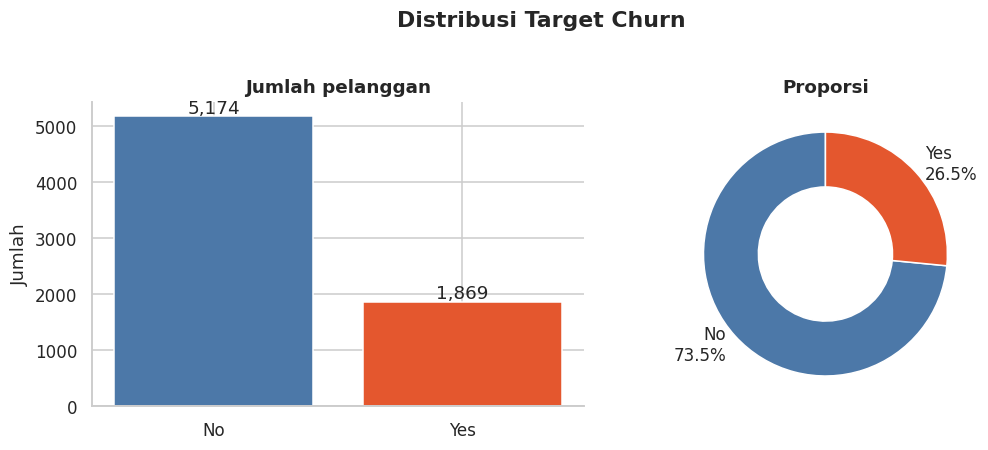

In [109]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
vc = df['Churn'].value_counts().reindex(['No', 'Yes'])
ax[0].bar(vc.index, vc.values, color=[COL['No'], COL['Yes']])
for i, v in enumerate(vc.values): ax[0].text(i, v + 60, f'{v:,}', ha='center')
ax[0].set_title('Jumlah pelanggan'); ax[0].set_ylabel('Jumlah')
ax[1].pie(vc.values, labels=[f'{k}\n{v/len(df):.1%}' for k, v in vc.items()], colors=[COL['No'], COL['Yes']], startangle=90, wedgeprops={'width': .45})
ax[1].set_title('Proporsi')
plt.suptitle('Distribusi Target Churn', y=1.02, fontweight='bold'); plt.tight_layout(); plt.show()

**Insight 1 — Distribusi target**
- Dari 7.043 pelanggan, **1.869 (26,5%) churn** dan 5.174 (73,5%) bertahan → imbalance moderat (≈ 2,8 : 1).
- **Implikasi bisnis:** hampir 1 dari 4 pelanggan hilang. Tebakan "tidak ada yang churn" akurat 73,5% tetapi tidak berguna, jadi evaluasi harus memakai PR-AUC, Recall, dan Precision, bukan akurasi.
- **Implikasi teknis:** gunakan stratified split dan penanganan imbalance (class weight, threshold tuning). Churn rate 26,5% juga menjadi *baseline* untuk menghitung lift.

### Visualisasi 2 — Churn berdasarkan Contract

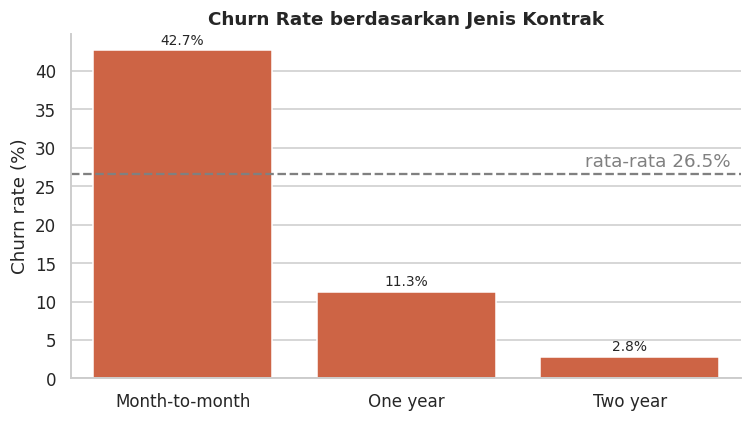

,churn_rate,n
Contract,,
Month-to-month,42.7,3875
One year,11.3,1473
Two year,2.8,1695


In [110]:
t = churn_table('Contract'); order = ['Month-to-month', 'One year', 'Two year']
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=t, x='Contract', y='churn_rate', order=order, color=COL['Yes'], ax=ax)
ax.axhline(overall*100, ls='--', c='grey'); ax.text(2.45, overall*100 + 1, f'rata-rata {overall:.1%}', ha='right', color='grey')
annotate_bars(ax); ax.set_ylabel('Churn rate (%)'); ax.set_title('Churn Rate berdasarkan Jenis Kontrak'); ax.set_xlabel('')
plt.tight_layout(); plt.show()
t.set_index('Contract').loc[order].round(1)

**Insight 2 — Contract**
- Churn rate **Month-to-month 42,7%**, One year 11,3%, Two year **2,8%** — selisih ±15× antara kontrak bulanan dan 2 tahun.
- Kontrak bulanan mencakup 3.875 pelanggan (55% basis) dan menyumbang mayoritas churn karena tidak ada hambatan untuk pindah.
- **Implikasi bisnis:** migrasi pelanggan bulanan ke kontrak 1–2 tahun (insentif diskon, bundling perangkat) adalah tuas retensi paling kuat. Perlu diingat bahwa ini asosiasi; pelanggan yang sudah loyal mungkin lebih mudah mengambil kontrak panjang.

### Visualisasi 3 — Churn berdasarkan Tenure

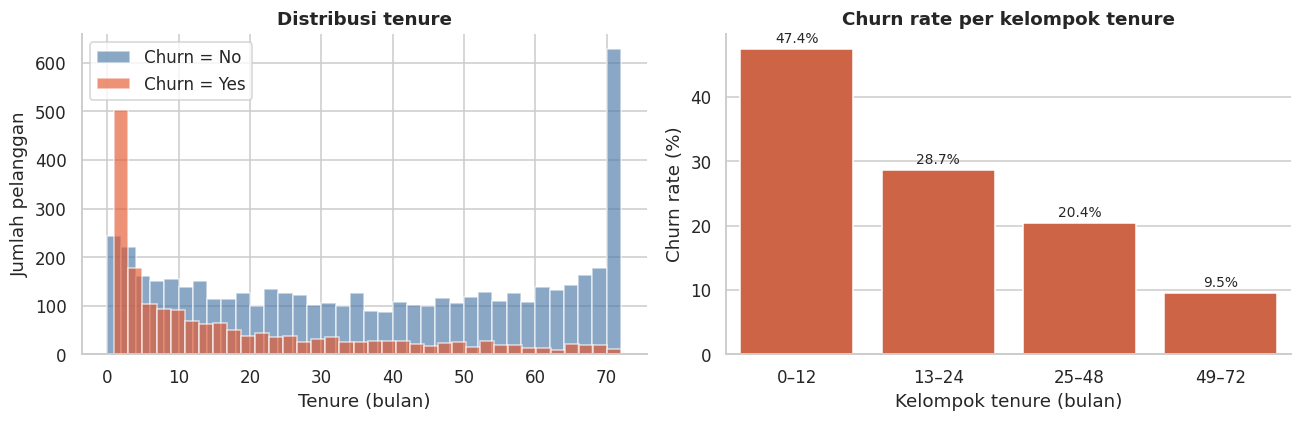

Churn                    No   Yes
median tenure (bulan)  38.0  10.0


,tenure,churn_rate,n
0,0–12,47.4,2186
1,13–24,28.7,1024
2,25–48,20.4,1594
3,49–72,9.5,2239


In [111]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k in ['No', 'Yes']:
    ax[0].hist(df.loc[df.Churn == k, 'tenure'], bins=36, alpha=.65, color=COL[k], label=f'Churn = {k}')
ax[0].set_xlabel('Tenure (bulan)'); ax[0].set_ylabel('Jumlah pelanggan'); ax[0].legend(); ax[0].set_title('Distribusi tenure')

bins = [-1, 12, 24, 48, 72]; labels = ['0–12', '13–24', '25–48', '49–72']
t = churn_table('tenure', bins, labels)
sns.barplot(data=t, x='tenure', y='churn_rate', color=COL['Yes'], ax=ax[1]); annotate_bars(ax[1])
ax[1].set_xlabel('Kelompok tenure (bulan)'); ax[1].set_ylabel('Churn rate (%)'); ax[1].set_title('Churn rate per kelompok tenure')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')['tenure'].median().rename('median tenure (bulan)').to_frame().T)
t.round(1)

**Insight 3 — Tenure**
- Median tenure pelanggan churn hanya **10 bulan** vs **38 bulan** pada pelanggan bertahan.
- Churn rate turun tajam seiring tenure: **47,4%** (0–12 bln) → 28,7% → 20,4% → **9,5%** (49–72 bln).
- Pelanggan di tahun pertama (2.186 orang, 31% basis) adalah segmen paling rapuh.
- **Implikasi bisnis:** program *onboarding* dan retensi dini (check-in 30/60/90 hari, penawaran di bulan 3–6) paling berdampak. Tenure akan menjadi fitur prediktor yang kuat.

### Visualisasi 4 — Churn berdasarkan MonthlyCharges

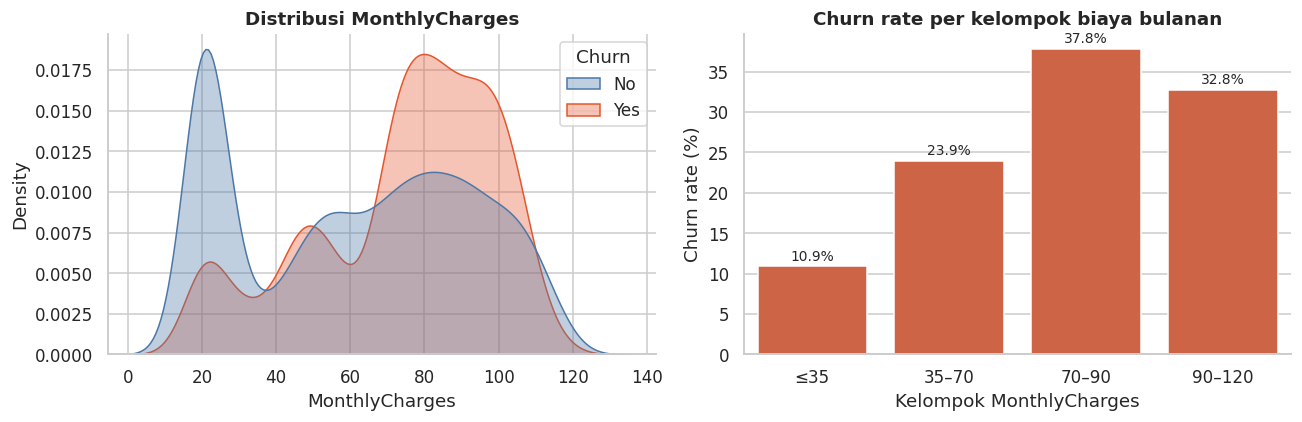

Churn                     No    Yes
median MonthlyCharges  64.43  79.65


,MonthlyCharges,churn_rate,n
0,≤35,10.9,1735
1,35–70,23.9,1725
2,70–90,37.8,1844
3,90–120,32.8,1739


In [112]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', palette=COL, common_norm=False, fill=True, alpha=.35, ax=ax[0], hue_order=['No', 'Yes'])
ax[0].set_title('Distribusi MonthlyCharges'); ax[0].set_xlabel('MonthlyCharges')
bins = [0, 35, 70, 90, 120]; labels = ['≤35', '35–70', '70–90', '90–120']
t = churn_table('MonthlyCharges', bins, labels)
sns.barplot(data=t, x='MonthlyCharges', y='churn_rate', color=COL['Yes'], ax=ax[1]); annotate_bars(ax[1])
ax[1].set_xlabel('Kelompok MonthlyCharges'); ax[1].set_ylabel('Churn rate (%)'); ax[1].set_title('Churn rate per kelompok biaya bulanan')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')['MonthlyCharges'].median().rename('median MonthlyCharges').to_frame().T.round(2))
t.round(1)

**Insight 4 — MonthlyCharges**
- Median biaya bulanan pelanggan churn **79,65** vs **64,43** pada pelanggan bertahan.
- Churn rate terendah pada biaya rendah (≤35: **10,9%**) dan puncaknya pada kelompok **70–90 (37,8%)**; kelompok 90–120 sedikit lebih rendah (32,8%) — hubungan tidak sepenuhnya linear.
- Pelanggan berbiaya rendah umumnya hanya berlangganan layanan telepon dasar (tanpa internet) sehingga lebih "lengket".
- **Implikasi bisnis:** pelanggan bertagihan tinggi sekaligus berisiko tinggi = pendapatan paling terancam. Mereka layak diprioritaskan dalam program retensi (paket value, bukan sekadar diskon). Biaya bulanan perlu dikombinasikan dengan fitur lain (jenis layanan, kontrak).

### Visualisasi 5 — Churn berdasarkan InternetService

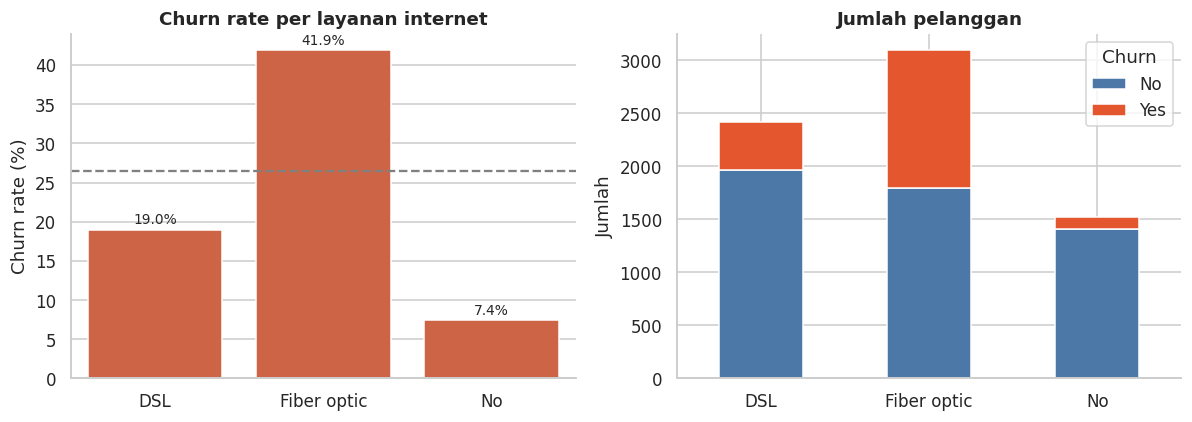

InternetService            DSL  Fiber optic     No
rata-rata MonthlyCharges  58.1         91.5  21.08


,churn_rate,n
InternetService,,
DSL,19.0,2421
Fiber optic,41.9,3096
No,7.4,1526


In [113]:
t = churn_table('InternetService'); order = ['DSL', 'Fiber optic', 'No']
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=t, x='InternetService', y='churn_rate', order=order, color=COL['Yes'], ax=ax[0]); annotate_bars(ax[0])
ax[0].axhline(overall*100, ls='--', c='grey'); ax[0].set_ylabel('Churn rate (%)'); ax[0].set_title('Churn rate per layanan internet'); ax[0].set_xlabel('')
ct = pd.crosstab(df['InternetService'], df['Churn']).reindex(order)
ct.plot(kind='bar', stacked=True, color=[COL['No'], COL['Yes']], ax=ax[1]); ax[1].set_title('Jumlah pelanggan'); ax[1].set_xlabel(''); ax[1].set_ylabel('Jumlah'); plt.setp(ax[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()
print(df.groupby('InternetService')['MonthlyCharges'].mean().round(2).rename('rata-rata MonthlyCharges').to_frame().T)
t.set_index('InternetService').loc[order].round(1)

**Insight 5 — InternetService**
- Pelanggan **Fiber optic** churn **41,9%**, hampir 2,2× DSL (**19,0%**), dan jauh di atas non-internet (**7,4%**).
- Fiber adalah segmen terbesar (3.096 pelanggan) dengan tagihan tertinggi — sehingga paling banyak berkontribusi pada hilangnya pendapatan.
- **Implikasi bisnis:** investigasi kualitas layanan fiber (stabilitas, harga vs kompetitor, dukungan teknis). Mekanisme pasti tidak dapat disimpulkan dari data ini, tetapi sinyalnya jelas. Layanan pendukung seperti OnlineSecurity dan TechSupport juga terkait churn yang lebih rendah (lihat analisis berikutnya).

### Visualisasi 6 — Churn berdasarkan PaymentMethod

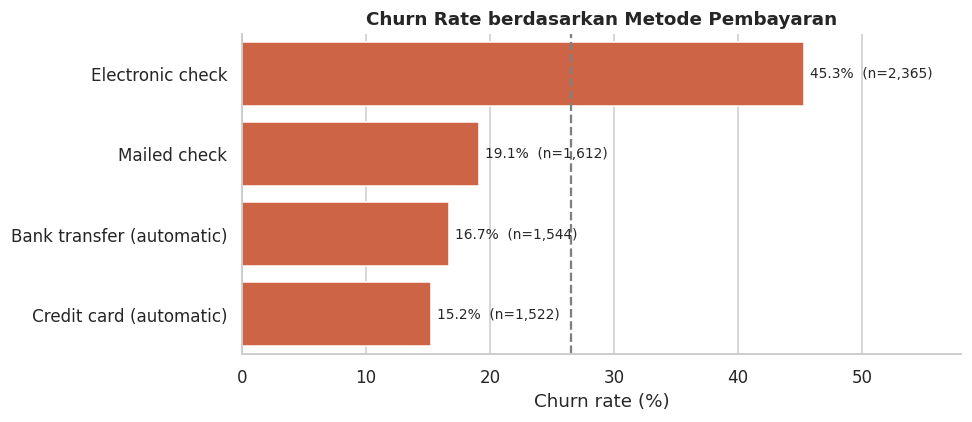

,PaymentMethod,churn_rate,n
2,Electronic check,45.3,2365
3,Mailed check,19.1,1612
0,Bank transfer (automatic),16.7,1544
1,Credit card (automatic),15.2,1522


In [114]:
t = churn_table('PaymentMethod').sort_values('churn_rate', ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=t, y='PaymentMethod', x='churn_rate', color=COL['Yes'], ax=ax)
for p, n in zip(ax.patches, t['n']):
    ax.text(p.get_width() + .5, p.get_y() + p.get_height()/2, f'{p.get_width():.1f}%  (n={n:,})', va='center', fontsize=9)
ax.axvline(overall*100, ls='--', c='grey'); ax.set_xlim(0, 58); ax.set_xlabel('Churn rate (%)'); ax.set_ylabel(''); ax.set_title('Churn Rate berdasarkan Metode Pembayaran')
plt.tight_layout(); plt.show()
t.round(1)

**Insight 6 — PaymentMethod**
- **Electronic check** churn **45,3%** (2.365 pelanggan), sedangkan pembayaran otomatis hanya **15–17%** (Credit card 15,2%, Bank transfer 16,7%); Mailed check 19,1%.
- Pembayaran otomatis menciptakan "gesekan" untuk berhenti dan mengurangi risiko lupa bayar; electronic check memerlukan aksi manual setiap bulan.
- **Implikasi bisnis:** dorong migrasi ke autopay (cashback, kemudahan). Electronic check berkorelasi dengan faktor lain (mis. kontrak bulanan, fiber), jadi efeknya sebagian tumpang tindih — bukan bukti sebab-akibat.

### Visualisasi 7 — Korelasi antarfitur numerik

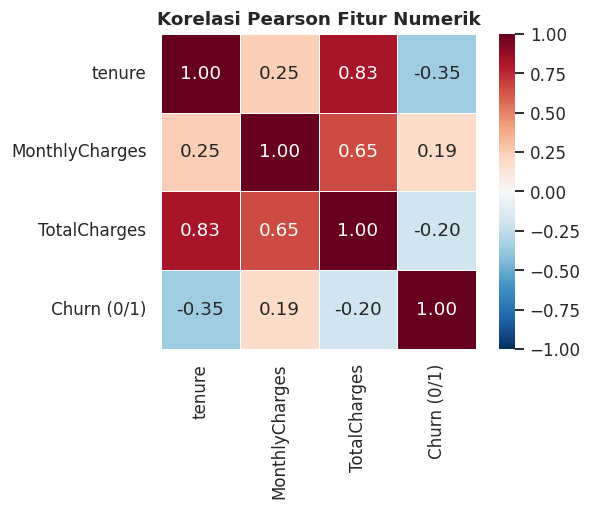

In [115]:
num = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].rename(columns={'ChurnFlag': 'Churn (0/1)'})
corr = num.corr()
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax)
ax.set_title('Korelasi Pearson Fitur Numerik'); plt.tight_layout(); plt.show()

**Insight 7 — Korelasi numerik**
- `tenure` berkorelasi **negatif** dengan churn (**−0,35**): semakin lama berlangganan, semakin kecil kemungkinan churn.
- `MonthlyCharges` berkorelasi positif lemah (**+0,19**); `TotalCharges` negatif (**−0,20**) karena pada dasarnya mencerminkan tenure.
- **`tenure` dan `TotalCharges` sangat berkorelasi (0,83)** → multikolinearitas. Penting bagi model linear (koefisien tidak stabil) dan untuk interpretasi. `TotalCharges` ≈ tenure × MonthlyCharges sehingga informasinya sebagian redundan.
- Korelasi linear untuk target tidak besar; hubungan kategorikal (kontrak, layanan) tampak jauh lebih kuat, sehingga model non-linear berpotensi bermanfaat.

### Visualisasi 8 — Distribusi TotalCharges terhadap Churn

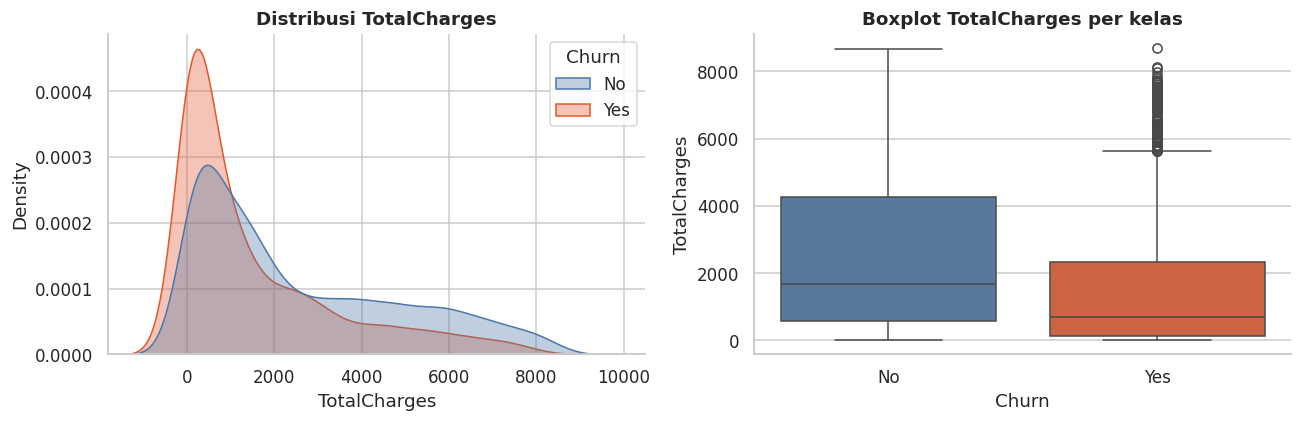

        count    mean     std   min    25%     50%     75%     max
Churn                                                             
No     5163.0  2555.3  2329.5  18.8  577.8  1683.6  4264.1  8672.4
Yes    1869.0  1531.8  1890.8  18.8  134.5   703.6  2331.3  8684.8


In [116]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=df.dropna(subset=['TotalCharges']), x='TotalCharges', hue='Churn', palette=COL, hue_order=['No', 'Yes'], common_norm=False, fill=True, alpha=.35, ax=ax[0])
ax[0].set_title('Distribusi TotalCharges')
sns.boxplot(data=df.dropna(subset=['TotalCharges']), x='Churn', y='TotalCharges', order=['No', 'Yes'], palette=COL, ax=ax[1])
ax[1].set_title('Boxplot TotalCharges per kelas')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')['TotalCharges'].describe().round(1))

**Insight 8 — TotalCharges**
- Distribusi sangat **miring ke kanan**; median pelanggan churn hanya **703,6** vs **1.683,6** pelanggan bertahan.
- Pelanggan churn menumpuk pada `TotalCharges` rendah karena mereka cenderung churn dini (tenure pendek), bukan karena bayar sedikit per bulan — bahkan MonthlyCharges mereka lebih tinggi (Insight 4).
- **Implikasi bisnis:** pelanggan churn belum sempat "membayar kembali" biaya akuisisinya. Retensi dini lebih berharga. `TotalCharges` sebaiknya dipakai berhati-hati bersama `tenure` (kolinear).

### Analisis tambahan — Layanan pendukung dan demografi

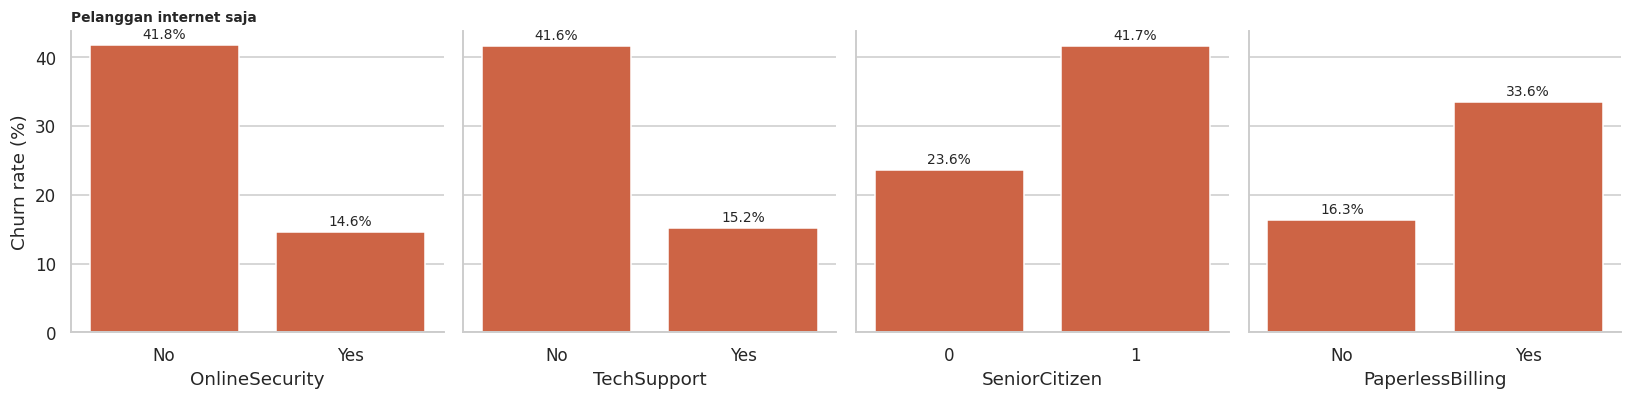

In [117]:
cols = ['OnlineSecurity', 'TechSupport', 'SeniorCitizen', 'PaperlessBilling']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, c in zip(axes, cols):
    d = df if c in ('SeniorCitizen', 'PaperlessBilling') else df[df.InternetService != 'No']
    t = d.groupby(c)['ChurnFlag'].mean().mul(100).reset_index()
    sns.barplot(data=t, x=c, y='ChurnFlag', color=COL['Yes'], ax=ax); annotate_bars(ax); ax.set_ylabel('Churn rate (%)'); ax.set_xlabel(c)
axes[0].set_title('Pelanggan internet saja', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

**Insight tambahan**
- Di antara pelanggan internet: yang **tanpa** OnlineSecurity churn sekitar 41,8% vs 14,6% yang memakai; **tanpa** TechSupport 41,6% vs 15,2% yang memakai.
- Senior citizen churn **41,7%** vs 23,6% non-senior; PaperlessBilling 33,6% vs 16,3%.
- Layanan pendukung berasosiasi dengan retensi lebih baik, namun pelanggan yang membeli add-on mungkin sudah lebih terikat (bias seleksi). Fitur `ServiceCount` pada Task 2 akan menangkap pola ini.

## Ringkasan Phase 1

| Aspek | Temuan utama |
|---|---|
| Kualitas data | Sangat baik: tanpa duplikat & outlier IQR; **satu masalah** → 11 baris `TotalCharges` kosong (pelanggan baru `tenure=0`) + tipe string. |
| Imbalance | 26,5% churn (1.869 dari 7.043) |
| Pendorong churn terkuat | Kontrak bulanan (42,7%), tenure ≤ 12 bulan (47,4%), fiber optic (41,9%), electronic check (45,3%), tanpa OnlineSecurity/TechSupport (~42%) |
| Catatan modeling | `tenure` ↔ `TotalCharges` korelasi 0,83 (multikolinear); butuh penanganan imbalance & threshold tuning; hindari akurasi sebagai metrik utama |

➡️ **Phase 2** akan membersihkan data, membuat fitur baru, membangun pipeline preprocessing, seleksi fitur, dan split 70/15/15.

---
# TASK 2 — Data Preparation & Feature Engineering

**Urutan kerja (dirancang untuk mencegah data leakage):**
1. **2.1 Data Cleaning** dan **2.2 Feature Engineering** — hanya transformasi *per baris* (tidak memakai statistik antar baris maupun target), sehingga aman dilakukan sebelum split.
2. **2.5 Validation Strategy** — split stratified 70/15/15 dilakukan **sebelum** langkah apa pun yang *belajar* dari data (seleksi fitur, scaling, encoding).
3. **2.4 Feature Selection** — hanya memakai **training set**.
4. **2.3 Encoding & Scaling** — `Pipeline` + `ColumnTransformer` yang di-*fit* hanya pada training set.

## 2.1 Data Cleaning

| # | Masalah (dari Task 1) | Tindakan | Alasan |
|---|---|---|---|
| 1 | `TotalCharges` bertipe string, 11 baris berisi string kosong | Konversi ke float dengan `pd.to_numeric(errors='coerce')` | Fitur ini jelas numerik. |
| 2 | 11 baris `TotalCharges` kosong, seluruhnya `tenure = 0` | Isi dengan **0,0** | Pelanggan baru belum pernah ditagih, sehingga total tagihan secara logis 0. Imputasi median/mean (≈1.397) akan keliru secara bisnis, dan menghapus baris akan membuang 11 pelanggan valid. Karena nilainya konstan (bukan statistik data), tidak ada leakage. |
| 3 | Duplikasi | Tidak ada (0 baris / 0 `customerID`) → tidak ada yang dihapus | Dicek ulang dengan assert. |
| 4 | Label turunan "No phone service" / "No internet service" pada 7 kolom layanan tambahan | Normalisasi menjadi **"No"** | Informasi tersebut sudah ada di `PhoneService` dan `InternetService`; menyisakan kategori ketiga hanya menambah dummy redundan dan mengacaukan penghitungan `ServiceCount`. |
| 5 | Target `Churn` berupa Yes/No | Encode menjadi 1/0 | Dibutuhkan model; 1 = churn (kelas positif). |
| 6 | `customerID` | Dibuang dari fitur | Identifier unik tanpa nilai prediktif; berisiko dihafal model. |
| 7 | Outlier numerik | **Tidak ditangani** | Tidak ada outlier IQR pada `tenure`, `MonthlyCharges`, `TotalCharges`; rentang nilai valid secara bisnis. Tidak ada alasan untuk menghapus atau memotong (*winsorize*) data. |

In [118]:
df_clean = df_raw.copy()

# 1-2) TotalCharges -> numerik; kosong (hanya tenure == 0) -> 0
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
n_missing_before = int(df_clean['TotalCharges'].isna().sum())
assert (df_clean.loc[df_clean['TotalCharges'].isna(), 'tenure'] == 0).all(), 'Missing TotalCharges harus semuanya tenure=0'
df_clean.loc[df_clean['TotalCharges'].isna(), 'TotalCharges'] = 0.0

# 3) Duplikasi
assert df_clean.duplicated().sum() == 0 and df_clean['customerID'].is_unique

# 4) Normalisasi label turunan pada kolom layanan tambahan
ADDON_COLS = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df_clean[ADDON_COLS] = df_clean[ADDON_COLS].replace({'No internet service': 'No', 'No phone service': 'No'})

# 5-6) Target 0/1 dan buang identifier
y_all = (df_clean['Churn'] == 'Yes').astype(int).rename('Churn')
customer_ids = df_clean['customerID']
df_clean = df_clean.drop(columns=['customerID', 'Churn'])

print(f'TotalCharges kosong sebelum: {n_missing_before} -> sesudah: {int(df_clean.TotalCharges.isna().sum())}')
print('Nilai unik kolom layanan tambahan:', sorted(pd.unique(df_clean[ADDON_COLS].values.ravel())))
print('Shape setelah cleaning (fitur):', df_clean.shape, '| churn rate:', f'{y_all.mean():.2%}')

TotalCharges kosong sebelum: 11 -> sesudah: 0
Nilai unik kolom layanan tambahan: ['No', 'Yes']
Shape setelah cleaning (fitur): (7043, 19) | churn rate: 26.54%


## 2.2 Feature Engineering

Lima fitur kandidat dibuat. Semuanya dihitung **hanya dari kolom pada baris yang sama** (tanpa target, tanpa statistik global) → tidak ada data leakage.

| Fitur | Cara perhitungan | Alasan & hubungan dengan churn | Manfaat bisnis |
|---|---|---|---|
| **`ServiceCount`** | Jumlah dari 7 layanan tambahan (`MultipleLines`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) yang bernilai "Yes" (0–7) | Semakin banyak layanan, secara teori semakin tinggi keterikatan pelanggan (*switching cost*). EDA menunjukkan layanan pendukung berasosiasi dengan churn lebih rendah; hubungan agregatnya diuji pada grafik di bawah. | Menyasar cross-sell/bundling pada pelanggan dengan layanan sedikit. |
| **`TenureGroup`** | Binning tenure: 0–12, 13–24, 25–48, 49–72 bulan (batas tetap berbasis logika tahunan, bukan dipelajari dari data) | Churn tidak turun linear terhadap tenure; tahun pertama jauh lebih rapuh (47,4% vs 9,5%). Grup menangkap non-linearitas untuk model linear. | Segmentasi siklus hidup: onboarding vs pelanggan setia. |
| **`IsLongTermContract`** | 1 jika `Contract` ∈ {One year, Two year}, selain itu 0 | Kontrak panjang = hambatan berpindah; churn 2,8–11,3% vs 42,7% untuk bulanan. | Indikator sederhana untuk target program migrasi kontrak. |
| **`IsAutoPay`** | 1 jika `PaymentMethod` mengandung "automatic" (bank transfer / credit card otomatis) | Pembayaran otomatis memiliki churn 15–17% vs 45,3% untuk electronic check. | Target kampanye migrasi ke autopay. |
| **`PriceChangeRatio`** | `MonthlyCharges ÷ (TotalCharges ÷ tenure)`; bernilai 1 bila `tenure = 0` | Membandingkan tarif **saat ini** dengan **rata-rata historis** yang dibayar. >1 berarti tagihan naik (upgrade/kenaikan harga) → hipotesis potensi *bill shock*; kekuatan sinyalnya diuji pada grafik di bawah dan pada feature importance (Task 4). | Mendeteksi pelanggan yang tagihannya naik dan butuh perhatian proaktif. |
| `AverageMonthlySpend` *(kandidat)* | `TotalCharges ÷ tenure` (= `MonthlyCharges` bila `tenure = 0`) | Rata-rata biaya bulanan historis. | Akan diuji pada seleksi fitur — dicurigai redundan dengan `MonthlyCharges`. |

> `ChargePerTenure` (MonthlyCharges ÷ tenure) tidak dipilih: nilainya meledak pada tenure kecil dan sebagian besar hanya mengulang informasi tenure.

In [119]:
df_fe = df_clean.copy()

df_fe['ServiceCount'] = (df_fe[ADDON_COLS] == 'Yes').sum(axis=1)

df_fe['TenureGroup'] = pd.cut(df_fe['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72']).astype(str)

df_fe['IsLongTermContract'] = df_fe['Contract'].isin(['One year', 'Two year']).astype(int)

df_fe['IsAutoPay'] = df_fe['PaymentMethod'].str.contains('automatic').astype(int)

df_fe['AverageMonthlySpend'] = np.where(df_fe['tenure'] > 0, df_fe['TotalCharges'] / df_fe['tenure'].replace(0, np.nan), df_fe['MonthlyCharges'])
df_fe['PriceChangeRatio'] = df_fe['MonthlyCharges'] / df_fe['AverageMonthlySpend']

NEW_FEATURES = ['ServiceCount', 'TenureGroup', 'IsLongTermContract', 'IsAutoPay', 'PriceChangeRatio', 'AverageMonthlySpend']
assert df_fe[NEW_FEATURES].isna().sum().sum() == 0 and np.isfinite(df_fe['PriceChangeRatio']).all()
assert 'Churn' not in df_fe.columns   # target tidak dipakai untuk membuat fitur
print(df_fe[NEW_FEATURES].describe(include='all').T.round(3))

                      count unique    top  freq       mean        std       min        25%      50%        75%       max
ServiceCount         7043.0    NaN    NaN   NaN   2.459747   2.045539       0.0        1.0      2.0        4.0       7.0
TenureGroup            7043      4  49-72  2239        NaN        NaN       NaN        NaN      NaN        NaN       NaN
IsLongTermContract   7043.0    NaN    NaN   NaN   0.449808    0.49751       0.0        0.0      0.0        1.0       1.0
IsAutoPay            7043.0    NaN    NaN   NaN   0.435326   0.495835       0.0        0.0      0.0        1.0       1.0
PriceChangeRatio     7043.0    NaN    NaN   NaN   1.002308   0.051248  0.635545   0.980882      1.0   1.020801  1.450628
AverageMonthlySpend  7043.0    NaN    NaN   NaN  64.762906  30.189796    13.775  35.935156  70.3375  90.174158     121.4


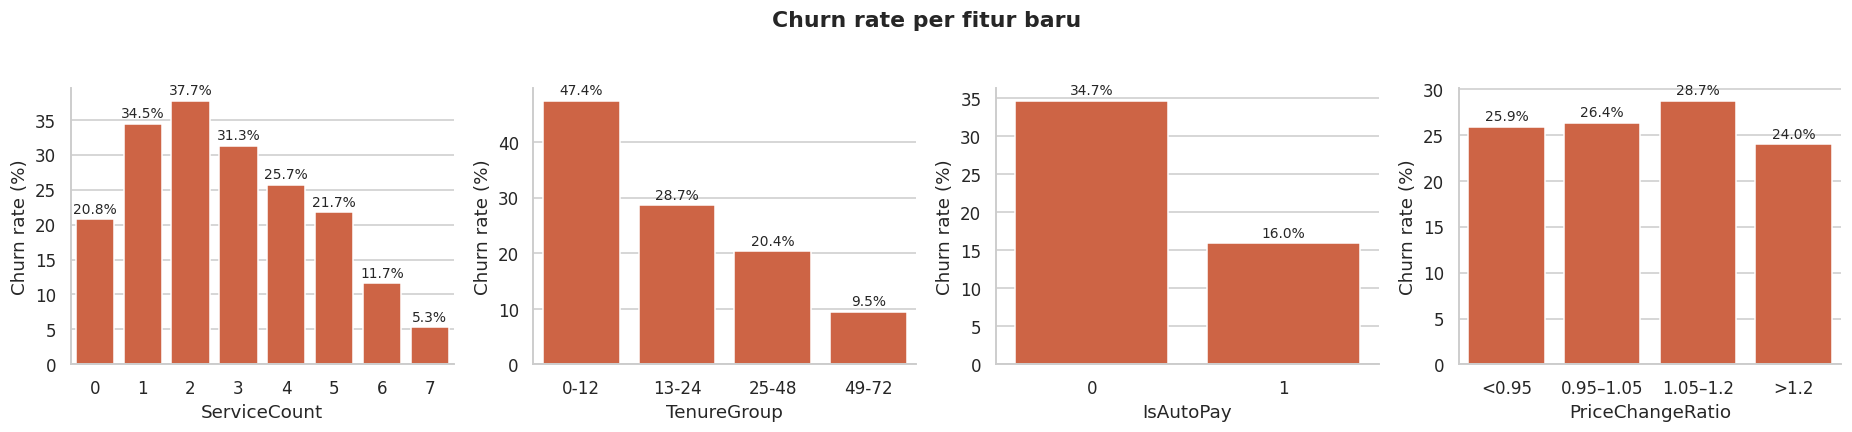

In [120]:
# Hubungan fitur baru dengan churn (eksplorasi deskriptif seluruh data — HANYA untuk pemahaman, bukan untuk fitting)
tmp = df_fe.assign(Churn=y_all)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, (c, order) in zip(ax[:3], [('ServiceCount', None), ('TenureGroup', ['0-12', '13-24', '25-48', '49-72']), ('IsAutoPay', None)]):
    t = tmp.groupby(c)['Churn'].mean().mul(100).reset_index()
    sns.barplot(data=t, x=c, y='Churn', order=order, color=COL['Yes'], ax=a); annotate_bars(a); a.set_ylabel('Churn rate (%)')
tmp['PCR_bin'] = pd.cut(tmp['PriceChangeRatio'], [0, .95, 1.05, 1.2, 3], labels=['<0.95', '0.95–1.05', '1.05–1.2', '>1.2'])
t = tmp.groupby('PCR_bin', observed=True)['Churn'].mean().mul(100).reset_index()
sns.barplot(data=t, x='PCR_bin', y='Churn', color=COL['Yes'], ax=ax[3]); annotate_bars(ax[3]); ax[3].set_xlabel('PriceChangeRatio'); ax[3].set_ylabel('Churn rate (%)')
plt.suptitle('Churn rate per fitur baru', y=1.03, fontweight='bold'); plt.tight_layout(); plt.show()

**Insight fitur baru** *(deskriptif, seluruh data)*
- **`ServiceCount` — hubungan tidak monoton:** churn 20,8% pada 0 layanan tambahan (umumnya pelanggan telepon/internet dasar), memuncak **37,7% pada 2 layanan**, lalu turun menjadi 21,7% (5 layanan), 11,7% (6) dan **5,3% (7 layanan)**. Pelanggan dengan banyak layanan jauh lebih "lengket", sedangkan pelanggan dengan 1–3 layanan adalah zona risiko. Pola non-linear ini menjadi alasan memakai model berbasis pohon.
- **`TenureGroup`:** menegaskan EDA — 47,4% (0–12 bulan) → 9,5% (49–72 bulan).
- **`IsAutoPay`:** churn **16,0%** (autopay) vs **34,7%** (non-autopay).
- **`PriceChangeRatio`:** hubungan univariat **lemah** — churn 25,9–28,7% pada kelompok <0,95 hingga 1,2 (kelompok >1,2 hanya 50 pelanggan, 24,0%). Fitur ini dipertahankan karena lolos aturan seleksi, tetapi **jangan diasumsikan sebagai pendorong utama churn**; kontribusinya akan dievaluasi lewat feature importance.

## 2.5 Validation Strategy — Split Data 70 / 15 / 15

- Tahap 1: pisahkan **70% train** dan **30% sementara** (`stratify=y`).
- Tahap 2: bagi 30% sementara menjadi **15% validation** dan **15% test** (`stratify`), `random_state = 42` pada keduanya.
- **Train**: fitting preprocessing, seleksi fitur, training model, cross-validation / tuning.
- **Validation**: perbandingan model dan penentuan threshold.
- **Test**: disentuh **hanya sekali** pada evaluasi akhir (Task 3.6).

In [121]:
from sklearn.model_selection import train_test_split

X_all = df_fe.copy()

X_train, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)

summary = pd.DataFrame({
    'split': ['Train', 'Validation', 'Test', 'Total'],
    'n': [len(X_train), len(X_val), len(X_test), len(X_all)],
    '% data': [len(X_train)/len(X_all)*100, len(X_val)/len(X_all)*100, len(X_test)/len(X_all)*100, 100],
    'n churn': [y_train.sum(), y_val.sum(), y_test.sum(), y_all.sum()],
    'churn rate (%)': [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100, y_all.mean()*100],
}).round(2)
summary

,split,n,% data,n churn,churn rate (%)
0,Train,4930,70.00,1308,26.53
1,Validation,1056,14.99,280,26.52
2,Test,1057,15.01,281,26.58
3,Total,7043,100.00,1869,26.54


## 2.4 Feature Selection (hanya pada training set)

Tiga sudut pandang dipakai untuk menilai tiap fitur:
1. **Mutual Information (MI)** terhadap churn — menangkap hubungan non-linear.
2. **Uji Chi-square** (fitur kategorikal/biner) — signifikansi statistik asosiasi dengan churn.
3. **Correlation analysis** antar fitur numerik — mendeteksi redundansi.

**Aturan keputusan (ditetapkan sebelum melihat hasil):** sebuah fitur dibuang jika (a) tidak signifikan secara statistik (p-value chi-square > 0,05) **dan** MI mendekati nol (< 0,005), atau (b) redundan dengan fitur lain (|r| ≥ 0,95).

In [122]:
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import chi2_contingency

cat_cols_all = [c for c in X_train.columns if X_train[c].dtype == 'object' or str(X_train[c].dtype).startswith('str')]
num_cols_all = [c for c in X_train.columns if c not in cat_cols_all]
binary_like  = ['SeniorCitizen', 'IsLongTermContract', 'IsAutoPay']
count_like   = ['ServiceCount']

# --- Mutual Information (training set saja) ---
X_mi = X_train.copy()
for c in cat_cols_all:
    X_mi[c] = X_mi[c].astype('category').cat.codes
is_discrete = [c in cat_cols_all + binary_like + count_like for c in X_mi.columns]
mi = pd.Series(mutual_info_classif(X_mi, y_train, discrete_features=is_discrete, random_state=RANDOM_STATE), index=X_mi.columns, name='MI')

# --- Chi-square (kategorikal + biner) ---
pvals = {c: chi2_contingency(pd.crosstab(X_train[c], y_train))[1] for c in cat_cols_all + binary_like}
sel = pd.DataFrame({'MI': mi, 'chi2_p': pd.Series(pvals)}).sort_values('MI', ascending=False)
sel['tipe'] = ['kategorikal' if c in cat_cols_all else 'biner' if c in binary_like else 'numerik' for c in sel.index]
sel.round(4)

,MI,chi2_p,tipe
Contract,0.0989,0.0000,kategorikal
IsLongTermContract,0.0931,0.0000,biner
tenure,0.0747,NaN,numerik
TenureGroup,0.0610,0.0000,kategorikal
InternetService,0.0568,0.0000,kategorikal
PaymentMethod,0.0465,0.0000,kategorikal
MonthlyCharges,0.0437,NaN,numerik
TotalCharges,0.0391,NaN,numerik
AverageMonthlySpend,0.0326,NaN,numerik
IsAutoPay,0.0251,0.0000,biner


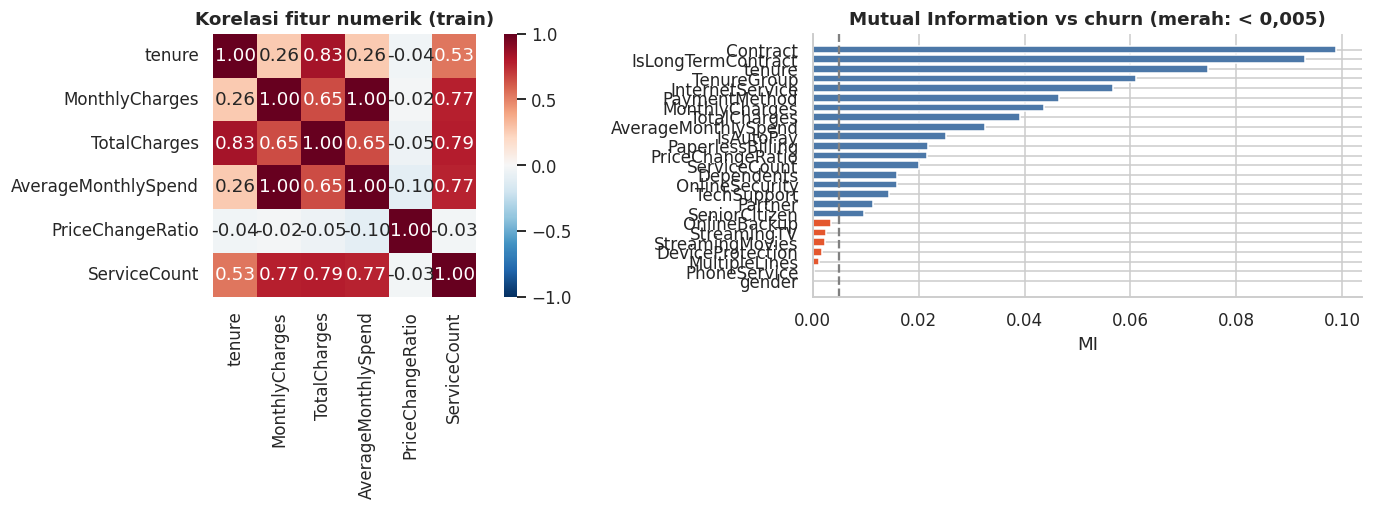

Pasangan fitur redundan (|r| >= 0.95): [('MonthlyCharges', 'AverageMonthlySpend', np.float64(0.996))]


In [123]:
# --- Correlation analysis antar fitur numerik (training set) ---
num_check = ['tenure', 'MonthlyCharges', 'TotalCharges', 'AverageMonthlySpend', 'PriceChangeRatio', 'ServiceCount']
corr_tr = X_train[num_check].corr()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1, 1]})
sns.heatmap(corr_tr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, ax=ax[0]); ax[0].set_title('Korelasi fitur numerik (train)')
mi_plot = sel['MI'].sort_values()
ax[1].barh(mi_plot.index, mi_plot.values, color=[COL['Yes'] if v < 0.005 else '#4C78A8' for v in mi_plot.values])
ax[1].axvline(0.005, ls='--', c='grey'); ax[1].set_title('Mutual Information vs churn (merah: < 0,005)'); ax[1].set_xlabel('MI')
plt.tight_layout(); plt.show()

# Pasangan dengan |r| >= 0.95
pairs = [(a, b, round(corr_tr.loc[a, b], 3)) for i, a in enumerate(num_check) for b in num_check[i+1:] if abs(corr_tr.loc[a, b]) >= 0.95]
print('Pasangan fitur redundan (|r| >= 0.95):', pairs)

In [124]:
# Terapkan aturan keputusan secara programatik
drop_stat = sel[(sel['chi2_p'] > 0.05) & (sel['MI'] < 0.005)].index.tolist()
drop_redundant = ['AverageMonthlySpend'] if any('AverageMonthlySpend' in p[:2] for p in pairs) else []
DROP_FEATURES = sorted(set(drop_stat + drop_redundant))
KEEP_FEATURES = [c for c in X_train.columns if c not in DROP_FEATURES]

print('Dibuang   :', DROP_FEATURES)
print(f'Dipertahankan: {len(KEEP_FEATURES)} dari {X_train.shape[1]} fitur')
print(KEEP_FEATURES)

Dibuang   : ['AverageMonthlySpend', 'PhoneService', 'gender']
Dipertahankan: 22 dari 25 fitur
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'ServiceCount', 'TenureGroup', 'IsLongTermContract', 'IsAutoPay', 'PriceChangeRatio']


### Hasil seleksi fitur

| Keputusan | Fitur | Alasan |
|---|---|---|
| **Dibuang** | `gender` | Chi-square p = 0,74 (tidak signifikan) dan MI ≈ 0 → tidak ada hubungan dengan churn. Juga menghindari risiko bias berbasis gender. |
| **Dibuang** | `PhoneService` | p = 0,11 (tidak signifikan), MI ≈ 0,0003. Informasinya terlalu umum (hampir semua pelanggan memilikinya). |
| **Dibuang** | `AverageMonthlySpend` | Korelasi **0,996** dengan `MonthlyCharges` → redundan; informasi barunya ditangkap oleh `PriceChangeRatio`. |
| **Dipertahankan** | `Contract`, `IsLongTermContract`, `tenure`, `TenureGroup`, `InternetService`, `MonthlyCharges`, `PaymentMethod`, `TotalCharges`, `IsAutoPay`, `PaperlessBilling`, `ServiceCount`, dst. | MI tertinggi dan chi-square sangat signifikan; sejalan dengan temuan EDA. |
| **Dipertahankan (catatan)** | `OnlineBackup`, `StreamingTV`, `StreamingMovies`, `DeviceProtection`, `MultipleLines` | MI rendah (< 0,005) tetapi chi-square **signifikan** (p < 0,05); tidak memenuhi aturan pembuangan. Juga menjadi penyusun `ServiceCount`. Model dapat memberi bobot kecil, regularisasi menangani sisanya. |
| **Dipertahankan (catatan)** | `TotalCharges` | Korelasi 0,83 dengan `tenure` (belum mencapai ambang 0,95). Dipertahankan; model linear memakai regularisasi L2 dan pohon tidak terpengaruh. Akan ditinjau kembali pada analisis koefisien. |
| **Dipertahankan** | Fitur baru: `ServiceCount`, `TenureGroup`, `IsLongTermContract`, `IsAutoPay`, `PriceChangeRatio` | Seluruhnya lolos aturan seleksi (lihat tabel MI/chi-square). |

> Seleksi memakai **training set saja**; validation dan test tidak dilihat sama sekali.

## 2.3 Encoding & Scaling — Pipeline Preprocessing

- **Numerik kontinu** (`tenure`, `MonthlyCharges`, `TotalCharges`, `ServiceCount`, `PriceChangeRatio`) → `StandardScaler`. Diperlukan untuk Logistic Regression; tidak merugikan model pohon.
- **Biner 0/1** (`SeniorCitizen`, `IsLongTermContract`, `IsAutoPay`) → *passthrough* (sudah dalam bentuk dummy).
- **Kategorikal** → `OneHotEncoder(drop='if_binary', handle_unknown='ignore')`. `drop='if_binary'` menghindari dummy ganda pada kolom Yes/No; `handle_unknown='ignore'` mencegah error bila data baru memuat kategori yang belum pernah terlihat.
- Target `Churn` **tidak** termasuk dalam kolom yang diproses.
- Seluruhnya dibungkus `ColumnTransformer`, sehingga `fit` hanya pada training set dan `transform` dipakai ulang pada validation/test.

In [125]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

NUM_SCALE = [c for c in ['tenure', 'MonthlyCharges', 'TotalCharges', 'ServiceCount', 'PriceChangeRatio'] if c in KEEP_FEATURES]
BIN_PASS  = [c for c in binary_like if c in KEEP_FEATURES]
CAT_OHE   = [c for c in cat_cols_all if c in KEEP_FEATURES]
assert sorted(NUM_SCALE + BIN_PASS + CAT_OHE) == sorted(KEEP_FEATURES), 'Setiap fitur terpilih harus tertangani preprocessor'

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), NUM_SCALE),
    ('bin', 'passthrough', BIN_PASS),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), CAT_OHE),
], verbose_feature_names_out=False).set_output(transform='pandas')

# FIT hanya pada training set
preprocessor.fit(X_train[KEEP_FEATURES])
Xt_train = preprocessor.transform(X_train[KEEP_FEATURES])
Xt_val   = preprocessor.transform(X_val[KEEP_FEATURES])
Xt_test  = preprocessor.transform(X_test[KEEP_FEATURES])
FEATURE_NAMES = Xt_train.columns.tolist()

print('Fitur numerik (scaled) :', NUM_SCALE)
print('Fitur biner (passthru) :', BIN_PASS)
print('Fitur kategorikal (OHE):', CAT_OHE)
print(f'\nShape setelah transform -> train {Xt_train.shape} | val {Xt_val.shape} | test {Xt_test.shape}')
print('Jumlah fitur akhir:', len(FEATURE_NAMES))
Xt_train.head(3).round(3)

Fitur numerik (scaled) : ['tenure', 'MonthlyCharges', 'TotalCharges', 'ServiceCount', 'PriceChangeRatio']
Fitur biner (passthru) : ['SeniorCitizen', 'IsLongTermContract', 'IsAutoPay']
Fitur kategorikal (OHE): ['Partner', 'Dependents', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']

Shape setelah transform -> train (4930, 32) | val (1056, 32) | test (1057, 32)
Jumlah fitur akhir: 32


,tenure,MonthlyCharges,TotalCharges,ServiceCount,PriceChangeRatio,SeniorCitizen,IsLongTermContract,IsAutoPay,Partner_Yes,Dependents_Yes,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_0-12,TenureGroup_13-24,TenureGroup_25-48,TenureGroup_49-72
5557,-1.115,0.504,-0.837,-0.722,0.803,0,0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2270,-1.196,0.724,-0.908,-0.237,3.445,1,0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
6930,-1.196,0.337,-0.910,-0.722,0.736,0,0,1,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


## Bukti Pencegahan Data Leakage

Pemeriksaan otomatis berikut harus lolos (jika gagal, notebook berhenti dengan `AssertionError`).

In [126]:
checks = {}

# 1) Tidak ada irisan indeks antar split
tr, va, te = set(X_train.index), set(X_val.index), set(X_test.index)
checks['Train / Val / Test saling lepas (tidak ada baris yang sama)'] = (not (tr & va)) and (not (tr & te)) and (not (va & te))
checks['Gabungan split = seluruh data (7.043 baris)'] = len(tr | va | te) == len(X_all) == 7043

# 2) Proporsi stratifikasi terjaga (selisih churn rate < 0.5 poin persen)
rates = [y_train.mean(), y_val.mean(), y_test.mean()]
checks['Churn rate tiap split berselisih < 0,5 pp (stratified)'] = (max(rates) - min(rates)) < 0.005

# 3) Target tidak ada di dalam fitur
checks['Target "Churn" tidak ada di fitur'] = ('Churn' not in X_all.columns) and ('Churn' not in FEATURE_NAMES)
checks['customerID tidak ada di fitur'] = 'customerID' not in X_all.columns

# 4) Scaler dipelajari dari TRAIN saja: mean scaler == mean train, bukan mean seluruh data
scaler = preprocessor.named_transformers_['num']
train_means = X_train[NUM_SCALE].mean().values
all_means   = X_all[NUM_SCALE].mean().values
checks['Mean StandardScaler = mean data TRAIN'] = np.allclose(scaler.mean_, train_means)
checks['Mean StandardScaler != mean seluruh data (bukti tidak melihat val/test)'] = not np.allclose(scaler.mean_, all_means, atol=1e-9)

# 5) Hasil scaling: train ~ mean 0 / std 1; val & test TIDAK persis 0/1 (karena memakai parameter train)
checks['Fitur train ter-scale: mean ≈ 0, std ≈ 1'] = np.allclose(Xt_train[NUM_SCALE].mean(), 0, atol=1e-8) and np.allclose(Xt_train[NUM_SCALE].std(ddof=0), 1, atol=1e-8)
checks['Fitur val/test tidak persis mean 0 (tidak di-fit ulang)'] = not np.allclose(Xt_val[NUM_SCALE].mean(), 0, atol=1e-8)

# 6) Fitur baru bersifat row-wise: nilai satu baris tidak berubah bila baris lain dihapus
probe = df_clean.sample(500, random_state=RANDOM_STATE)
recomputed = (probe[ADDON_COLS] == 'Yes').sum(axis=1)
checks['ServiceCount identik jika dihitung ulang pada subset (row-wise)'] = (recomputed.values == df_fe.loc[probe.index, 'ServiceCount'].values).all()

# 7) Seleksi fitur memakai index train saja
checks['Seleksi fitur (MI & chi²) dihitung pada X_train'] = (len(X_mi) == len(X_train))

res = pd.DataFrame({'Pemeriksaan': list(checks), 'Lolos': ['✅' if v else '❌' for v in checks.values()]})
display(res)
assert all(checks.values()), 'Ada pemeriksaan leakage yang gagal!'
print('Semua pemeriksaan leakage LOLOS.')

,Pemeriksaan,Lolos
0,Train / Val / Test saling lepas (tidak ada bar...,✅
1,Gabungan split = seluruh data (7.043 baris),✅
2,"Churn rate tiap split berselisih < 0,5 pp (str...",✅
3,"Target ""Churn"" tidak ada di fitur",✅
4,customerID tidak ada di fitur,✅
5,Mean StandardScaler = mean data TRAIN,✅
6,Mean StandardScaler != mean seluruh data (bukt...,✅
7,"Fitur train ter-scale: mean ≈ 0, std ≈ 1",✅
8,Fitur val/test tidak persis mean 0 (tidak di-f...,✅
9,ServiceCount identik jika dihitung ulang pada ...,✅


Semua pemeriksaan leakage LOLOS.


### Penjelasan bukti leakage

| Risiko leakage | Pencegahan |
|---|---|
| Statistik scaling bocor dari val/test | `StandardScaler` di-fit hanya pada train; mean scaler terbukti sama dengan mean train dan berbeda dari mean seluruh data. |
| Seleksi fitur melihat data test | MI dan chi-square dihitung pada `X_train` saja. |
| Fitur baru memakai informasi target / antar baris | Semua fitur dihitung per baris tanpa `Churn`; `TenureGroup` memakai batas tetap berbasis logika bisnis, bukan kuantil data. |
| Baris yang sama muncul di beberapa split | Indeks train/val/test terbukti saling lepas. |
| Imputasi memakai statistik global | `TotalCharges` diisi konstanta 0 berdasarkan logika bisnis (`tenure = 0`), bukan mean/median. |
| Resampling bocor ke val/test | Dijaga di Phase 3: resampling (bila dipakai) hanya pada train; pada rencana ini penanganan imbalance memakai `class_weight` dan threshold tuning. |

## Ringkasan Phase 2

| Aspek | Hasil |
|---|---|
| Cleaning | `TotalCharges` → numerik (11 kosong diisi 0 karena `tenure = 0`); label turunan dinormalisasi; tidak ada duplikat/outlier yang dihapus; `customerID` dibuang. |
| Fitur baru | 5 fitur dipertahankan (`ServiceCount`, `TenureGroup`, `IsLongTermContract`, `IsAutoPay`, `PriceChangeRatio`) + 1 kandidat (`AverageMonthlySpend`) yang dibuang karena redundan. |
| Seleksi fitur | 3 fitur dibuang (`gender`, `PhoneService`, `AverageMonthlySpend`); 22 dipertahankan. |
| Split | Train 4.930 / Validation 1.056 / Test 1.057, churn rate ≈ 26,5% di semua split. |
| Pipeline | `ColumnTransformer` (StandardScaler + passthrough + OneHotEncoder), di-fit pada train. |
| Leakage | 11 pemeriksaan otomatis lolos. |

➡️ **Phase 3** akan membangun model (Dummy, Logistic Regression, Random Forest/XGBoost), menangani imbalance, tuning, optimasi threshold, evaluasi test, dan tabel perbandingan.

---
# TASK 3 — Modeling, Comparison & Optimization

**Prinsip kerja Phase ini**
- Semua model dibungkus dalam `Pipeline(preprocessor → model)` sehingga scaling/encoding di-fit ulang **di dalam setiap fold** saat cross-validation dan hanya memakai data training.
- **Train** → fitting & cross-validation/tuning. **Validation** → membandingkan model dan menentukan threshold. **Test** → hanya dipakai **sekali** di 3.6.
- Metrik wajib: ROC-AUC, PR-AUC, Precision, Recall, F1, Confusion Matrix.

In [127]:
import time
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

# Data mentah terpilih (pipeline akan melakukan preprocessing sendiri)
Xtr, Xva, Xte = X_train[KEEP_FEATURES], X_val[KEEP_FEATURES], X_test[KEEP_FEATURES]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # CV hanya pada TRAIN
N_JOBS = -1

def make_pipe(model):
    return Pipeline([('prep', clone(preprocessor)), ('model', model)])

def metrics_at(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0)}

pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f'Rasio negatif:positif pada train = {pos_ratio:.3f}  (dipakai untuk scale_pos_weight XGBoost)')

Rasio negatif:positif pada train = 2.769  (dipakai untuk scale_pos_weight XGBoost)


## 3.1 Model Development & 3.2 Handling Class Imbalance

**Model:**
1. **Baseline** — `DummyClassifier(strategy='stratified')`: menebak acak sesuai proporsi kelas; ini setara dengan "menghubungi pelanggan secara acak".
2. **Logistic Regression** (interpretable, regularisasi L2).
3. **Random Forest** dan **XGBoost** (tree-based ensemble; menangkap non-linearitas seperti pola `ServiceCount` yang terlihat di Phase 2).

**Penanganan imbalance (26,5% churn):** dibandingkan dua skenario pada model yang mendukungnya — *tanpa bobot* vs `class_weight='balanced'` (XGBoost: `scale_pos_weight`). Setelah itu **threshold tuning** (3.5) dipakai sebagai mekanisme utama kedua.

**Mengapa bukan SMOTE?** Data didominasi fitur kategorikal/biner hasil one-hot; SMOTE menginterpolasi nilai kontinu sehingga menghasilkan dummy pecahan yang tidak realistis, menambah kompleksitas, dan imbalance ini hanya moderat (≈2,8 : 1). Pembobotan kelas memberi efek serupa tanpa membuat data sintetis, dan otomatis hanya berlaku pada data training (tidak mungkin bocor ke validation/test).

In [128]:
models = {
    'Dummy (stratified)':          DummyClassifier(strategy='stratified', random_state=RANDOM_STATE),
    'LogReg (no weight)':          LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'LogReg (balanced)':           LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'RandomForest (no weight)':    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    'RandomForest (balanced)':     RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=N_JOBS),
    'XGBoost (no weight)':         XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=N_JOBS),
    'XGBoost (scale_pos_weight)':  XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, scale_pos_weight=pos_ratio, eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=N_JOBS),
}

fitted, val_proba, train_time, rows = {}, {}, {}, []
for name, m in models.items():
    pipe = make_pipe(m)
    t0 = time.perf_counter(); pipe.fit(Xtr, y_train); train_time[name] = time.perf_counter() - t0
    fitted[name] = pipe
    val_proba[name] = pipe.predict_proba(Xva)[:, 1]
    rows.append({'Model': name, **metrics_at(y_val, val_proba[name], 0.5), 'Train time (s)': train_time[name]})

base_results = pd.DataFrame(rows).set_index('Model')
base_results.round(4)

,ROC-AUC,PR-AUC,Precision,Recall,F1,Train time (s)
Model,,,,,,
Dummy (stratified),0.4958,0.2636,0.2590,0.2571,0.2581,0.0278
LogReg (no weight),0.8467,0.6331,0.6516,0.5679,0.6069,0.0454
LogReg (balanced),0.8461,0.6328,0.5044,0.8250,0.6260,0.0500
RandomForest (no weight),0.8325,0.6170,0.6229,0.5250,0.5698,1.2803
RandomForest (balanced),0.8319,0.6177,0.6062,0.4893,0.5415,1.9570
XGBoost (no weight),0.8378,0.6376,0.6189,0.5393,0.5763,0.2588
XGBoost (scale_pos_weight),0.8360,0.6348,0.5505,0.7786,0.6450,0.8088


## 3.3 Model Evaluation pada Validation Set
Tabel di atas memakai **threshold default 0,5 hanya sebagai titik awal** (belum dioptimalkan, lihat 3.5). ROC-AUC dan PR-AUC tidak bergantung threshold sehingga ideal untuk membandingkan kualitas *ranking*. Berikut kurva dan confusion matrix.

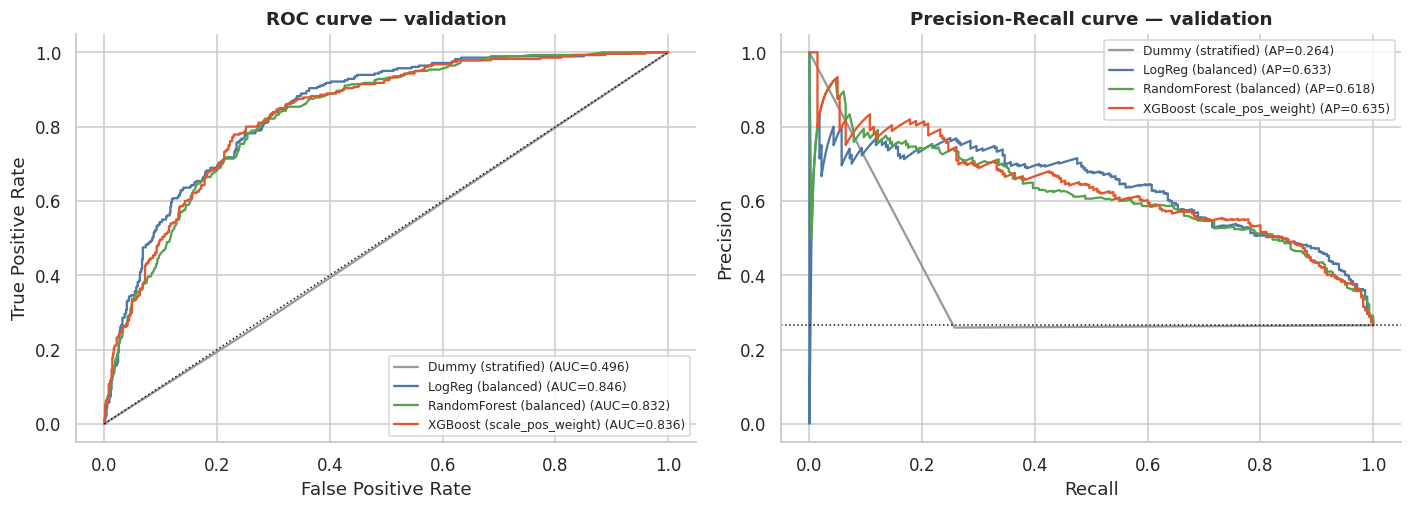

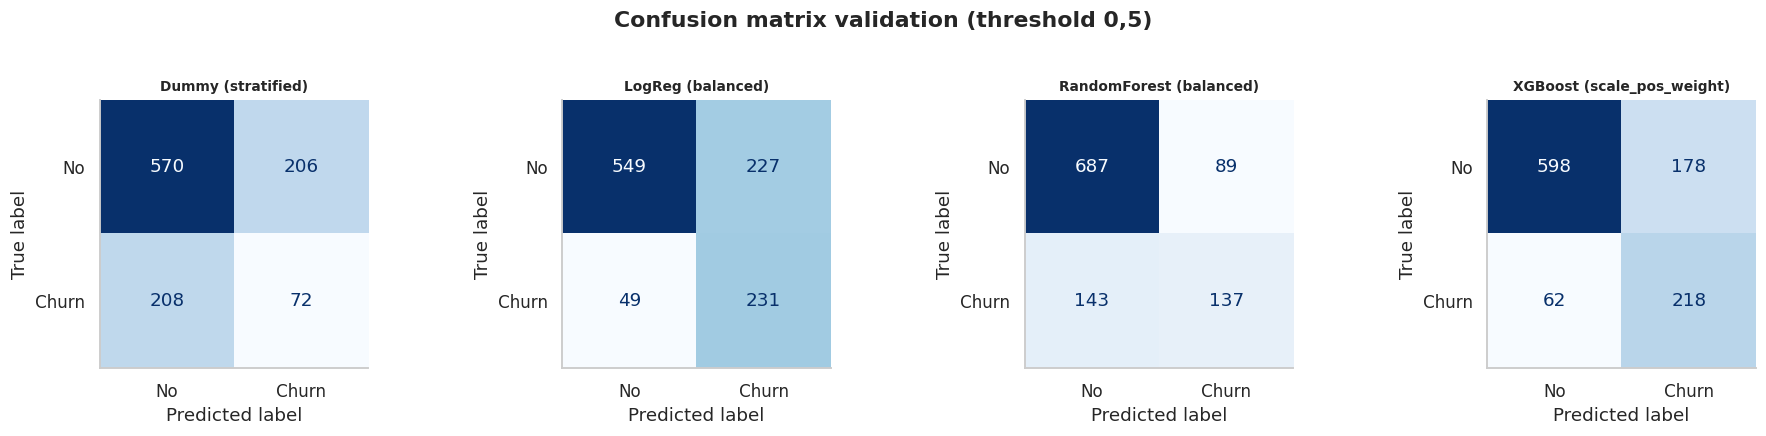

In [129]:
show = ['Dummy (stratified)', 'LogReg (balanced)', 'RandomForest (balanced)', 'XGBoost (scale_pos_weight)']
pal = {'Dummy (stratified)': '#999999', 'LogReg (balanced)': '#4C78A8', 'RandomForest (balanced)': '#54A24B', 'XGBoost (scale_pos_weight)': '#E4572E'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for n in show:
    fpr, tpr, _ = roc_curve(y_val, val_proba[n]); ax[0].plot(fpr, tpr, color=pal[n], label=f"{n} (AUC={base_results.loc[n,'ROC-AUC']:.3f})")
    p, r, _ = precision_recall_curve(y_val, val_proba[n]); ax[1].plot(r, p, color=pal[n], label=f"{n} (AP={base_results.loc[n,'PR-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], 'k:', lw=1); ax[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC curve — validation'); ax[0].legend(fontsize=8)
ax[1].axhline(y_val.mean(), color='k', ls=':', lw=1); ax[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall curve — validation'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for a, n in zip(axes, show):
    cm = confusion_matrix(y_val, (val_proba[n] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['No', 'Churn']).plot(ax=a, colorbar=False, cmap='Blues'); a.set_title(n, fontsize=9); a.grid(False)
plt.suptitle('Confusion matrix validation (threshold 0,5)', y=1.03, fontweight='bold'); plt.tight_layout(); plt.show()

**Interpretasi perbandingan awal (validation)**
- **Baseline acak** memberi ROC-AUC 0,496 dan PR-AUC 0,264 — persis tingkat kebetulan (PR-AUC acak ≈ churn rate 26,5%). Semua model ML mencapai ROC-AUC ≈ 0,83–0,85 dan PR-AUC ≈ 0,62–0,64, yaitu **±2,4× lebih baik dari acak** dalam hal PR-AUC.
- **Efek penanganan imbalance:** membobot kelas hampir **tidak mengubah kualitas ranking** (PR-AUC Logistic Regression 0,633 → 0,633; Random Forest 0,617 → 0,622; XGBoost 0,638 → 0,635), tetapi menggeser keseimbangan precision/recall pada threshold 0,5 (Logistic Regression: recall 0,568 → 0,825, precision 0,652 → 0,504). Artinya bobot kelas bekerja seperti menurunkan threshold. Karena threshold nantinya ditentukan berdasarkan biaya dan kapasitas (3.5), **threshold tuning menjadi mekanisme utama** penanganan imbalance, bobot kelas hanya pelengkap.
- Pada threshold 0,5 model ber-bobot memiliki F1 lebih tinggi (mis. XGBoost 0,645 vs 0,576) hanya karena recall naik; ini bukan peningkatan kemampuan membedakan churn.
- Perbedaan antar model ML kecil (PR-AUC selisih ≤ 0,02). Validation hanya berisi 280 pelanggan churn sehingga selisih sekecil itu masih dalam rentang *noise* sampling; perbandingan akan dikuatkan dengan cross-validation pada train di 3.4.

## 3.4 Hyperparameter Tuning
`RandomizedSearchCV` (40 kandidat × 5-fold stratified CV) dijalankan pada **training set saja**, dengan skor optimasi **PR-AUC (`average_precision`)** karena paling sesuai untuk kelas minoritas dan untuk tugas *ranking* prioritas retensi. Dilakukan pada **Random Forest** dan **XGBoost**; Logistic Regression dituning ringan pada `C` (grid kecil) sebagai pembanding yang adil.

In [130]:
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import GridSearchCV

searches = {}
# ---------- Random Forest ----------
rf_space = {'model__n_estimators': randint(200, 700), 'model__max_depth': [None, 4, 6, 8, 10, 14],
            'model__min_samples_split': randint(2, 30), 'model__min_samples_leaf': randint(1, 20),
            'model__max_features': ['sqrt', 'log2', 0.3, 0.5], 'model__class_weight': ['balanced', 'balanced_subsample', None]}
rf_pipe = make_pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
searches['RandomForest'] = RandomizedSearchCV(rf_pipe, rf_space, n_iter=40, scoring='average_precision', cv=CV, random_state=RANDOM_STATE, n_jobs=N_JOBS, refit=True)

# ---------- XGBoost ----------
xgb_space = {'model__n_estimators': randint(100, 500), 'model__max_depth': randint(2, 7), 'model__learning_rate': loguniform(0.01, 0.2),
             'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.5, 0.5), 'model__min_child_weight': randint(1, 15),
             'model__reg_lambda': loguniform(0.5, 20), 'model__scale_pos_weight': [1.0, pos_ratio]}
xgb_pipe = make_pipe(XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=1))
searches['XGBoost'] = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=40, scoring='average_precision', cv=CV, random_state=RANDOM_STATE, n_jobs=N_JOBS, refit=True)

# ---------- Logistic Regression ----------
lr_pipe = make_pipe(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
searches['LogReg'] = GridSearchCV(lr_pipe, {'model__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10], 'model__class_weight': ['balanced', None]}, scoring='average_precision', cv=CV, n_jobs=N_JOBS, refit=True)

search_time = {}
for k, s in searches.items():
    t0 = time.perf_counter(); s.fit(Xtr, y_train); search_time[k] = time.perf_counter() - t0
    print(f'{k:13s} | best CV PR-AUC = {s.best_score_:.4f} | waktu search = {search_time[k]:.1f}s')

RandomForest  | best CV PR-AUC = 0.6667 | waktu search = 302.1s
XGBoost       | best CV PR-AUC = 0.6682 | waktu search = 36.6s
LogReg        | best CV PR-AUC = 0.6644 | waktu search = 2.7s


In [131]:
# Parameter sebelum vs sesudah tuning + skor (CV = train; Validation = out-of-sample)
before_name = {'RandomForest': 'RandomForest (balanced)', 'XGBoost': 'XGBoost (scale_pos_weight)', 'LogReg': 'LogReg (balanced)'}
cmp_rows = []
for k, s in searches.items():
    b = before_name[k]
    # skor CV pada konfigurasi default (sebelum tuning) -> pembanding yang sebanding dengan best_score_ (PR-AUC CV pada train)
    cv_before = __import__('sklearn.model_selection', fromlist=['cross_val_score']).cross_val_score(make_pipe(clone(models[b])), Xtr, y_train, cv=CV, scoring='average_precision', n_jobs=N_JOBS).mean()
    pv = searches[k].predict_proba(Xva)[:, 1]
    cmp_rows.append({'Model': k, 'CV PR-AUC sebelum': cv_before, 'CV PR-AUC sesudah': s.best_score_,
                     'Val PR-AUC sebelum': base_results.loc[b, 'PR-AUC'], 'Val PR-AUC sesudah': average_precision_score(y_val, pv),
                     'Val ROC-AUC sebelum': base_results.loc[b, 'ROC-AUC'], 'Val ROC-AUC sesudah': roc_auc_score(y_val, pv)})
tuning_table = pd.DataFrame(cmp_rows).set_index('Model')
display(tuning_table.round(4))

for k, s in searches.items():
    print(f'\n=== {k} ===')
    print('Parameter sebelum tuning :', {kk: (round(vv, 3) if isinstance(vv, float) else vv) for kk, vv in models[before_name[k]].get_params().items()
                                        if kk in ([p.replace('model__', '') for p in s.param_distributions] if hasattr(s, 'param_distributions') else [p.replace('model__', '') for p in s.param_grid])})
    print('Parameter terbaik        :', {kk.replace('model__', ''): (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in s.best_params_.items()})

,CV PR-AUC sebelum,CV PR-AUC sesudah,Val PR-AUC sebelum,Val PR-AUC sesudah,Val ROC-AUC sebelum,Val ROC-AUC sesudah
Model,,,,,,
RandomForest,0.6335,0.6667,0.6177,0.6444,0.8319,0.8482
XGBoost,0.6416,0.6682,0.6348,0.6521,0.8360,0.8513
LogReg,0.6622,0.6644,0.6328,0.6352,0.8461,0.8477



=== RandomForest ===
Parameter sebelum tuning : {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Parameter terbaik        : {'class_weight': 'balanced_subsample', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'min_samples_split': 22, 'n_estimators': 407}

=== XGBoost ===
Parameter sebelum tuning : {'colsample_bytree': None, 'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': None, 'n_estimators': 300, 'reg_lambda': None, 'scale_pos_weight': np.float64(2.769), 'subsample': None}
Parameter terbaik        : {'colsample_bytree': np.float64(0.5025), 'learning_rate': np.float64(0.0162), 'max_depth': 3, 'min_child_weight': 2, 'n_estimators': 409, 'reg_lambda': np.float64(2.6144), 'scale_pos_weight': 1.0, 'subsample': np.float64(0.6897)}

=== LogReg ===
Parameter sebelum tuning : {'C': 1.0, 'class_weight': 'balanced'}
Parameter terbaik        : {'C': 10, 'class_weight': 

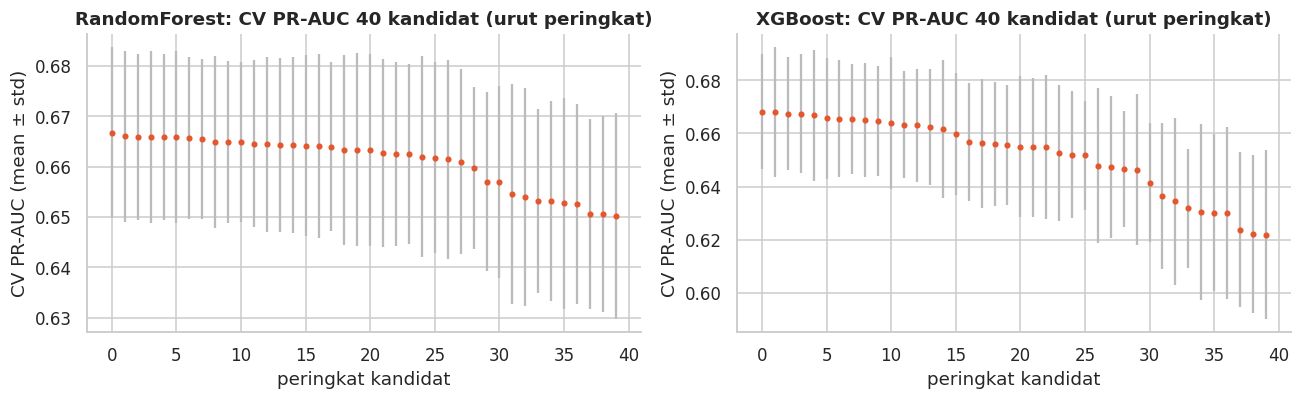

In [132]:
# Stabilitas hasil tuning: 10 konfigurasi teratas Random Forest & XGBoost
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, k in zip(ax, ['RandomForest', 'XGBoost']):
    r = pd.DataFrame(searches[k].cv_results_).sort_values('rank_test_score').head(40)
    a.errorbar(range(len(r)), r['mean_test_score'], yerr=r['std_test_score'], fmt='o', ms=3, color=COL['Yes'], ecolor='#bbb')
    a.set_title(f'{k}: CV PR-AUC 40 kandidat (urut peringkat)'); a.set_xlabel('peringkat kandidat'); a.set_ylabel('CV PR-AUC (mean ± std)')
plt.tight_layout(); plt.show()

**Interpretasi tuning**
- **Random Forest:** PR-AUC CV 0,634 → 0,666 dan validation 0,622 → 0,644 (ROC-AUC 0,832 → 0,849). Parameter terbaik membuat pohon **lebih dangkal dan lebih teregulasi** (`max_depth` 8, `min_samples_leaf` 8, `min_samples_split` 22) dibanding default (pohon penuh) → mengurangi overfitting.
- **XGBoost:** PR-AUC CV 0,642 → 0,668 dan validation 0,635 → 0,652 (ROC-AUC 0,836 → 0,851). Konfigurasi terbaik: pohon dangkal (`max_depth` 3), `learning_rate` kecil (0,016), subsampling dan regularisasi L2. Menariknya, tuning memilih `scale_pos_weight = 1` (tanpa bobot), konsisten dengan temuan bahwa bobot kelas tidak memperbaiki ranking.
- **Logistic Regression:** hampir tidak berubah (CV 0,662 → 0,664; validation 0,633 → 0,635) karena model linear sudah mencapai batasnya; `C` besar (10) dengan tanpa bobot kelas dipilih.
- Skor CV selalu sedikit lebih tinggi daripada validation (≈ 0,016–0,029), wajar karena ukuran sampel validation kecil dan hasil tuning sedikit "menyesuaikan" CV. Ketiga model sangat dekat: **XGBoost > Random Forest > Logistic Regression** hanya selisih ≈ 0,017 PR-AUC di validation.
- Tuning memberi peningkatan **moderat** (+0,017 hingga +0,032 PR-AUC), bukan lompatan; sebagian besar sinyal churn sudah bisa ditangkap model linear sederhana. Hal ini penting untuk pertimbangan interpretability di Task 4.

## 3.5 Threshold Optimization (berbasis kapasitas & biaya program retensi)

Threshold default 0,5 **tidak dipakai**. Threshold ditentukan di **validation set** dari tiga sudut pandang bisnis.

**Asumsi kampanye retensi** (eksplisit & dapat diubah; dibuat sebelum melihat hasil, bukan disetel agar hasil tampak bagus):

| Parameter | Nilai | Keterangan |
|---|---|---|
| Biaya per pelanggan yang dihubungi | **50** (satuan mata uang dataset) | Waktu agen + insentif/diskon. |
| Peluang pelanggan churn berhasil dipertahankan | **30%** | Tidak semua yang dihubungi bisa dipertahankan; pelanggan non-churn yang dihubungi tidak menghasilkan manfaat. |
| Horizon pendapatan yang diselamatkan | **6 bulan** × `MonthlyCharges` pelanggan tersebut | Konservatif (pendapatan, bukan laba; tidak memodelkan umur pelanggan penuh). |
| Kapasitas tim retensi | maks. **30%** dari basis pelanggan | Keterbatasan agen/anggaran. |

**Manfaat bersih (expected net benefit)** = Σ (TP × 30% × MonthlyCharges × 6) − (jumlah dihubungi × 50).
**Aturan pemilihan:** threshold yang memaksimalkan expected net benefit pada validation, dengan batas kapasitas ≤ 30% pelanggan dihubungi.

In [133]:
CAMPAIGN = {'cost_per_contact': 50.0, 'success_rate': 0.30, 'months': 6, 'capacity': 0.30}

def net_benefit(y_true, scores, monthly, thr, camp=CAMPAIGN):
    y_true = np.asarray(y_true); monthly = np.asarray(monthly)
    contact = scores >= thr
    saved = (contact & (y_true == 1)) * monthly * camp['success_rate'] * camp['months']
    return saved.sum() - camp['cost_per_contact'] * contact.sum()

def threshold_sweep(y_true, scores, monthly, thr_grid=None, camp=CAMPAIGN):
    thr_grid = np.round(np.arange(0.05, 0.96, 0.01), 2) if thr_grid is None else thr_grid
    out = []
    for t in thr_grid:
        pred = scores >= t; n = pred.sum()
        out.append({'threshold': t, 'contacted': int(n), 'contacted_%': n / len(scores) * 100,
                    'precision': precision_score(y_true, pred, zero_division=0), 'recall': recall_score(y_true, pred, zero_division=0),
                    'f1': f1_score(y_true, pred, zero_division=0), 'net_benefit': net_benefit(y_true, scores, monthly, t, camp)})
    return pd.DataFrame(out)

def best_threshold(sw, camp=CAMPAIGN):
    ok = sw[sw['contacted_%'] <= camp['capacity'] * 100]
    return ok.loc[ok['net_benefit'].idxmax()] if len(ok) and ok['net_benefit'].max() > 0 else None

def topk_table(y_true, scores, monthly, ks=(0.05, 0.10, 0.20, 0.30), camp=CAMPAIGN):
    y_true = np.asarray(y_true); order = np.argsort(-scores); base = y_true.mean(); rows = []
    for k in ks:
        n = int(round(k * len(scores))); idx = order[:n]; tp = y_true[idx].sum()
        rows.append({'top-k': f'{int(k*100)}%', 'contacted': n, 'TP': int(tp), 'precision': tp / n, 'recall': tp / y_true.sum(), 'lift': (tp / n) / base,
                     'net_benefit': (y_true[idx] * np.asarray(monthly)[idx]).sum() * camp['success_rate'] * camp['months'] - camp['cost_per_contact'] * n})
    return pd.DataFrame(rows)

monthly_val = X_val['MonthlyCharges'].values
tuned_val_proba = {k: s.predict_proba(Xva)[:, 1] for k, s in searches.items()}
sweeps = {k: threshold_sweep(y_val, p, monthly_val) for k, p in tuned_val_proba.items()}
best_thr = {k: best_threshold(sw) for k, sw in sweeps.items()}
for k, b in best_thr.items():
    print(f'{k:13s}: threshold optimal = {b.threshold:.2f} | dihubungi {b["contacted_%"]:.1f}% | precision {b.precision:.3f} | recall {b.recall:.3f} | net benefit {b.net_benefit:,.0f}')

RandomForest : threshold optimal = 0.65 | dihubungi 27.7% | precision 0.608 | recall 0.636 | net benefit 10,516
XGBoost      : threshold optimal = 0.41 | dihubungi 29.6% | precision 0.601 | recall 0.671 | net benefit 10,957
LogReg       : threshold optimal = 0.49 | dihubungi 24.1% | precision 0.651 | recall 0.593 | net benefit 11,063


In [134]:
# Pemilihan model kandidat final: PR-AUC validation tertinggi; jika selisih <= 0.005 pilih yang lebih interpretable (aturan ditetapkan di awal)
interp_rank = {'LogReg': 0, 'RandomForest': 1, 'XGBoost': 2}   # 0 = paling interpretable
val_pr = {k: average_precision_score(y_val, p) for k, p in tuned_val_proba.items()}
top = max(val_pr.values())
cands = [k for k, v in val_pr.items() if top - v <= 0.005]
FINAL_MODEL_NAME = min(cands, key=lambda k: interp_rank[k])
print('PR-AUC validation (tuned):', {k: round(v, 4) for k, v in val_pr.items()})
print('Kandidat dalam selisih 0.005:', cands, '->  MODEL FINAL:', FINAL_MODEL_NAME)
final_pipe = searches[FINAL_MODEL_NAME].best_estimator_
final_val_scores = tuned_val_proba[FINAL_MODEL_NAME]
FINAL_THRESHOLD = float(best_thr[FINAL_MODEL_NAME].threshold)
print(f'THRESHOLD FINAL (dari validation) = {FINAL_THRESHOLD:.2f}')

PR-AUC validation (tuned): {'RandomForest': np.float64(0.6444), 'XGBoost': np.float64(0.6521), 'LogReg': np.float64(0.6352)}
Kandidat dalam selisih 0.005: ['XGBoost'] ->  MODEL FINAL: XGBoost
THRESHOLD FINAL (dari validation) = 0.41


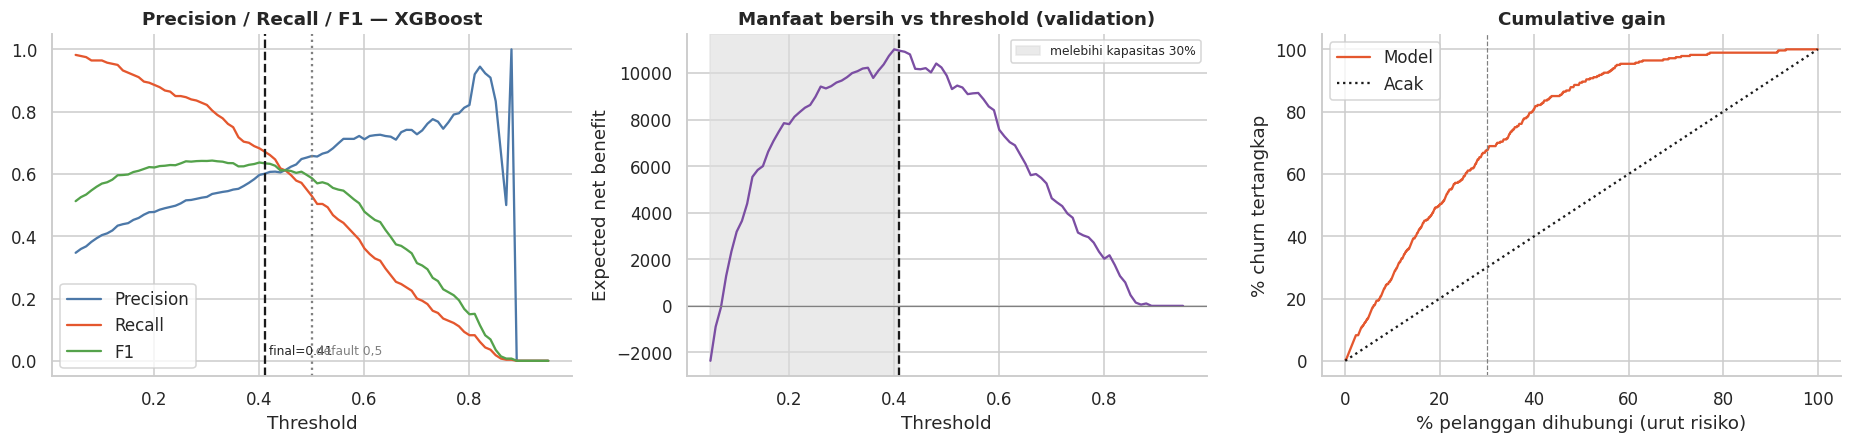

Perbandingan beberapa threshold (validation):


,contacted,contacted_%,precision,recall,f1,net_benefit
threshold,,,,,,
0.20,519,49.148,0.478,0.886,0.621,7803.15
0.30,437,41.383,0.526,0.821,0.642,9672.86
0.40,320,30.303,0.597,0.682,0.637,11014.31
0.41,313,29.640,0.601,0.671,0.634,10957.15
0.50,225,21.307,0.658,0.529,0.586,9885.42
0.60,142,13.447,0.711,0.361,0.479,7562.35
0.70,77,7.292,0.727,0.200,0.314,4619.81



Pendekatan kapasitas top-k% (validation):


,contacted,TP,precision,recall,lift,net_benefit
top-k,,,,,,
5%,53,40,0.755,0.143,2.846,3388.91
10%,106,76,0.717,0.271,2.704,6007.51
20%,211,140,0.664,0.500,2.502,9425.05
30%,317,189,0.596,0.675,2.249,10894.76


In [135]:
sw = sweeps[FINAL_MODEL_NAME]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(sw.threshold, sw.precision, label='Precision', color='#4C78A8'); ax[0].plot(sw.threshold, sw.recall, label='Recall', color=COL['Yes']); ax[0].plot(sw.threshold, sw.f1, label='F1', color='#54A24B')
ax[0].axvline(FINAL_THRESHOLD, color='k', ls='--'); ax[0].axvline(0.5, color='grey', ls=':'); ax[0].set(xlabel='Threshold', title=f'Precision / Recall / F1 — {FINAL_MODEL_NAME}'); ax[0].legend()
ax[0].text(FINAL_THRESHOLD, 0.02, f' final={FINAL_THRESHOLD:.2f}', fontsize=8); ax[0].text(0.5, 0.02, ' default 0,5', fontsize=8, color='grey')
ax[1].plot(sw.threshold, sw.net_benefit, color='#7B4EA3'); ax[1].axvline(FINAL_THRESHOLD, color='k', ls='--'); ax[1].axhline(0, color='grey', lw=.8)
cap_thr = sw[sw['contacted_%'] <= CAMPAIGN['capacity']*100].threshold.min(); ax[1].axvspan(0.05, cap_thr, color='#ddd', alpha=.6, label='melebihi kapasitas 30%'); ax[1].legend(fontsize=8)
ax[1].set(xlabel='Threshold', ylabel='Expected net benefit', title='Manfaat bersih vs threshold (validation)')
order = np.argsort(-final_val_scores); gain = np.cumsum(np.asarray(y_val)[order]) / y_val.sum(); x = np.arange(1, len(y_val) + 1) / len(y_val)
ax[2].plot(x * 100, gain * 100, color=COL['Yes'], label='Model'); ax[2].plot([0, 100], [0, 100], 'k:', label='Acak'); ax[2].axvline(30, color='grey', ls='--', lw=.8)
ax[2].set(xlabel='% pelanggan dihubungi (urut risiko)', ylabel='% churn tertangkap', title='Cumulative gain'); ax[2].legend()
plt.tight_layout(); plt.show()

print('Perbandingan beberapa threshold (validation):')
pick = sw[sw.threshold.isin([0.20, 0.30, 0.40, 0.50, 0.60, 0.70, FINAL_THRESHOLD])].drop_duplicates('threshold')
display(pick.round(3).set_index('threshold'))
print('\nPendekatan kapasitas top-k% (validation):')
display(topk_table(y_val, final_val_scores, monthly_val).round(3).set_index('top-k'))

**Interpretasi threshold optimization**
- Aturan terpilih: **model final = XGBoost tuned** (PR-AUC validation tertinggi 0,652; selisih dengan Random Forest 0,008 dan Logistic Regression 0,017, keduanya > 0,005 sehingga aturan "pilih yang lebih interpretable bila hampir sama" tidak berlaku).
- **Threshold final = 0,41**, yang menghubungi **29,6%** pelanggan (batas kapasitas 30%), dengan **precision 0,601, recall 0,671**, manfaat bersih diharapkan **10.957** pada validation. Threshold 0,40 sebenarnya memberi manfaat bersih sedikit lebih tinggi (11.014) tetapi menghubungi 30,3% pelanggan sehingga melampaui kapasitas.
- Dibanding threshold default 0,5 (manfaat bersih 9.885, recall hanya 0,529), threshold 0,41 menaikkan manfaat bersih ±11% dan menangkap lebih banyak churn. Threshold yang lebih rendah (0,20–0,30) menghubungi 41–49% pelanggan, recall tinggi (0,82–0,89) tetapi precision turun ke 0,48–0,53 sehingga biaya kontak membengkak dan manfaat bersih turun.
- **Pendekatan top-k:** menghubungi **10% pelanggan teratas** menangkap 27,1% churn dengan precision 71,7% (**lift 2,7×**); **20%** teratas menangkap 50,0% churn (precision 66,4%, lift 2,5×); **30%** menangkap 67,5% churn (lift 2,2×). Kurva cumulative gain berada jauh di atas diagonal acak.
- **Catatan asumsi:** angka manfaat bersih sangat bergantung pada asumsi biaya, peluang berhasil, dan horizon (lihat tabel asumsi). Sensitivitas asumsi dibahas di Task 4. Skor model dari data berbobot/tidak berbobot bukan probabilitas terkalibrasi; threshold di sini dipakai sebagai batas skor, bukan klaim probabilitas churn sebenarnya.

## 3.6 Final Test Evaluation
Model final dan threshold sudah **terkunci** dari validation (3.5). Test set dipakai **satu kali** di sini, tanpa tuning ulang.

Model final      : XGBoost
Threshold final  : 0.41  (ditentukan di validation)
Parameter model  : {'colsample_bytree': np.float64(0.5025), 'learning_rate': np.float64(0.0162), 'max_depth': 3, 'min_child_weight': 2, 'n_estimators': 409, 'reg_lambda': np.float64(2.6144), 'scale_pos_weight': 1.0, 'subsample': np.float64(0.6897)}


,ROC-AUC,PR-AUC,Precision,Recall,F1
Validation,0.8513,0.6521,0.6006,0.6714,0.6341
Test,0.8433,0.6705,0.6255,0.5943,0.6095


TN=676  FP=100  FN=114  TP=167   | dihubungi = 267 (25.3% dari test)


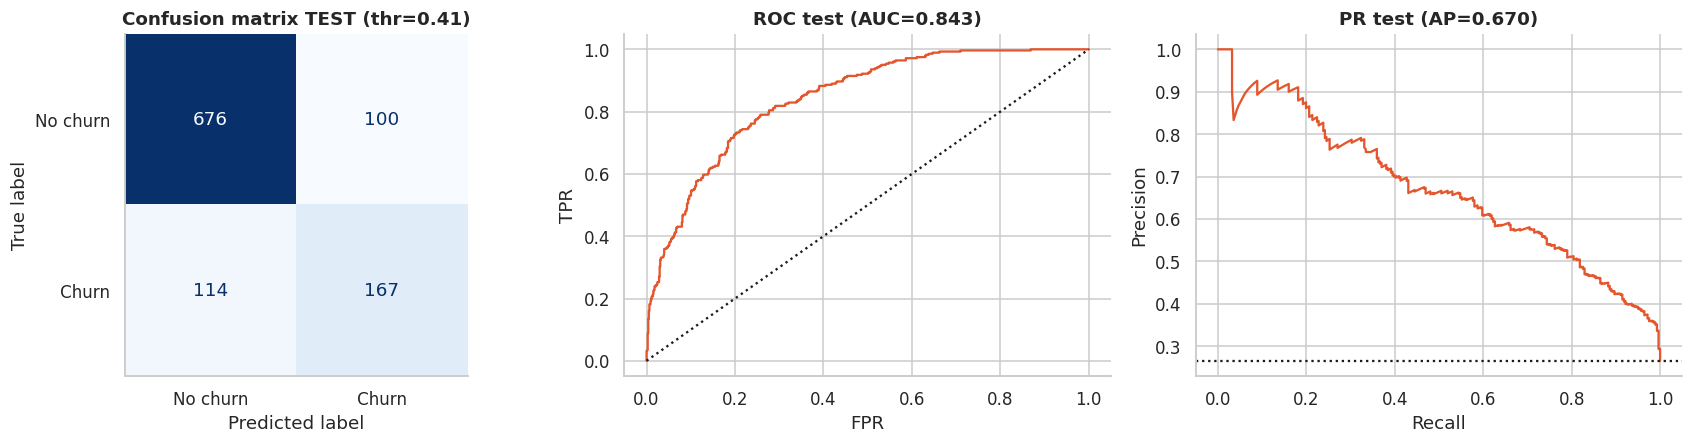

Kapasitas top-k% pada TEST:


,contacted,TP,precision,recall,lift,net_benefit
top-k,,,,,,
5%,53,48,0.906,0.171,3.407,4326.80
10%,106,83,0.783,0.295,2.945,6366.25
20%,211,140,0.664,0.498,2.496,8729.89
30%,317,186,0.587,0.662,2.207,9742.58


Expected net benefit TEST pada threshold final (asumsi 3.5): 9,916


In [136]:
print(f'Model final      : {FINAL_MODEL_NAME}')
print(f'Threshold final  : {FINAL_THRESHOLD:.2f}  (ditentukan di validation)')
print('Parameter model  :', {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in searches[FINAL_MODEL_NAME].best_params_.items()})

test_scores = final_pipe.predict_proba(Xte)[:, 1]
test_pred = (test_scores >= FINAL_THRESHOLD).astype(int)
test_metrics = metrics_at(y_test, test_scores, FINAL_THRESHOLD)
val_metrics_final = metrics_at(y_val, final_val_scores, FINAL_THRESHOLD)
monthly_test = X_test['MonthlyCharges'].values

cm_test = confusion_matrix(y_test, test_pred); tn, fp, fn, tp = cm_test.ravel()
res = pd.DataFrame({'Validation': val_metrics_final, 'Test': test_metrics}).T
display(res.round(4))
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}   | dihubungi = {tp+fp} ({(tp+fp)/len(y_test):.1%} dari test)')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ConfusionMatrixDisplay(cm_test, display_labels=['No churn', 'Churn']).plot(ax=ax[0], colorbar=False, cmap='Blues'); ax[0].set_title(f'Confusion matrix TEST (thr={FINAL_THRESHOLD:.2f})'); ax[0].grid(False)
fpr, tpr, _ = roc_curve(y_test, test_scores); ax[1].plot(fpr, tpr, color=COL['Yes']); ax[1].plot([0, 1], [0, 1], 'k:'); ax[1].set(title=f"ROC test (AUC={test_metrics['ROC-AUC']:.3f})", xlabel='FPR', ylabel='TPR')
p, r, _ = precision_recall_curve(y_test, test_scores); ax[2].plot(r, p, color=COL['Yes']); ax[2].axhline(y_test.mean(), color='k', ls=':'); ax[2].set(title=f"PR test (AP={test_metrics['PR-AUC']:.3f})", xlabel='Recall', ylabel='Precision')
plt.tight_layout(); plt.show()

print('Kapasitas top-k% pada TEST:'); display(topk_table(y_test, test_scores, monthly_test).round(3).set_index('top-k'))
nb_test = net_benefit(y_test, test_scores, monthly_test, FINAL_THRESHOLD)
print(f'Expected net benefit TEST pada threshold final (asumsi 3.5): {nb_test:,.0f}')

**Interpretasi evaluasi test (sekali pakai)**

| Metrik | Validation | **Test** |
|---|---|---|
| ROC-AUC | 0,851 | **0,843** |
| PR-AUC | 0,652 | **0,671** |
| Precision (thr 0,41) | 0,601 | **0,626** |
| Recall (thr 0,41) | 0,671 | **0,594** |
| F1 (thr 0,41) | 0,634 | **0,610** |

- **Confusion matrix test:** TN = 676, FP = 100, FN = 114, TP = 167. Dari 1.057 pelanggan test, 267 (25,3%) akan dihubungi; 167 di antaranya benar-benar churn (precision 62,6%), dan 167 dari 281 churn aktual tertangkap (recall 59,4%).
- **Generalisasi baik:** ROC-AUC turun hanya 0,008, PR-AUC justru naik 0,019 (kemungkinan *noise* sampling; test hanya berisi 281 churn). Tidak terlihat overfitting yang berarti terhadap validation.
- **Recall turun 7,7 poin** (0,671 → 0,594) sementara precision naik; threshold 0,41 menghubungi 25,3% pelanggan di test vs 29,6% di validation karena distribusi skor sedikit berbeda. Ini menunjukkan threshold berbasis nilai skor ikut bergeser antar sampel; untuk produksi, threshold berbasis **kapasitas (top-k%)** lebih stabil dibanding threshold nilai tetap.
- Pada pendekatan kapasitas test: top 10% → precision 78,3% (lift 2,9×), top 20% → recall 49,8% (lift 2,5×), top 30% → recall 66,2% (lift 2,2×).
- Manfaat bersih diharapkan pada test: **9.916** (positif), berdasarkan asumsi 3.5. Ini estimasi pendapatan yang diproyeksikan, bukan keuntungan aktual.
- Tidak ada tuning ulang yang dilakukan berdasarkan hasil test.

## 3.7 Model Comparison
Tabel membandingkan seluruh model pada **validation set**. Untuk model ML, Precision/Recall/F1 dihitung pada **threshold optimal masing-masing** (aturan 3.5 yang sama), sehingga perbandingan adil. Baseline Dummy memakai prediksi labelnya langsung. Training time = waktu `fit` pipeline dengan parameter terbaik pada train set.

In [137]:
interp = {'Dummy (baseline)': ('Tidak relevan', 'Tebakan acak sesuai proporsi kelas; setara menghubungi pelanggan secara acak.'),
          'LogReg': ('Tinggi', 'Koefisien dapat dibaca langsung; ranking kuat, stabil, dan cepat.'),
          'RandomForest': ('Sedang', 'Menangkap interaksi non-linear; importance global, lebih sulit dijelaskan per pelanggan.'),
          'XGBoost': ('Rendah–Sedang', 'Ranking terbaik (PR-AUC tertinggi); dapat dijelaskan dengan SHAP/permutation importance.')}
rows = []
d = 'Dummy (stratified)'
rows.append({'Nama model': 'Dummy (baseline)', **metrics_at(y_val, val_proba[d], 0.5), 'Threshold': 0.50, 'Training time (s)': train_time[d],
             'Interpretability': interp['Dummy (baseline)'][0], 'Keterangan': interp['Dummy (baseline)'][1]})
for k, s in searches.items():
    t0 = time.perf_counter(); clone(s.best_estimator_).fit(Xtr, y_train); tt = time.perf_counter() - t0
    thr = float(best_thr[k].threshold)
    rows.append({'Nama model': f'{k} (tuned)' + (' ★ FINAL' if k == FINAL_MODEL_NAME else ''), **metrics_at(y_val, tuned_val_proba[k], thr), 'Threshold': thr,
                 'Training time (s)': tt, 'Interpretability': interp[k][0], 'Keterangan': interp[k][1]})
comparison = pd.DataFrame(rows).set_index('Nama model')
display(comparison.round(4))

print('\nEvaluasi akhir model final pada TEST set:')
display(pd.DataFrame([{'Nama model': f'{FINAL_MODEL_NAME} (tuned) — TEST', **test_metrics, 'Threshold': FINAL_THRESHOLD}]).set_index('Nama model').round(4))

,ROC-AUC,PR-AUC,Precision,Recall,F1,Threshold,Training time (s),Interpretability,Keterangan
Nama model,,,,,,,,,
Dummy (baseline),0.4958,0.2636,0.2590,0.2571,0.2581,0.50,0.0278,Tidak relevan,Tebakan acak sesuai proporsi kelas; setara men...
RandomForest (tuned),0.8482,0.6444,0.6075,0.6357,0.6213,0.65,1.8456,Sedang,Menangkap interaksi non-linear; importance glo...
XGBoost (tuned) ★ FINAL,0.8513,0.6521,0.6006,0.6714,0.6341,0.41,0.2589,Rendah–Sedang,Ranking terbaik (PR-AUC tertinggi); dapat dije...
LogReg (tuned),0.8477,0.6352,0.6510,0.5929,0.6206,0.49,0.0364,Tinggi,"Koefisien dapat dibaca langsung; ranking kuat,..."



Evaluasi akhir model final pada TEST set:


,ROC-AUC,PR-AUC,Precision,Recall,F1,Threshold
Nama model,,,,,,
XGBoost (tuned) — TEST,0.8433,0.6705,0.6255,0.5943,0.6095,0.41


**Interpretasi tabel perbandingan**
- Seluruh model ML jauh mengungguli baseline (PR-AUC 0,635–0,652 vs 0,264).
- **XGBoost** memiliki ROC-AUC (0,851) dan PR-AUC (0,652) tertinggi, dengan recall tertinggi (0,671) pada threshold optimal; **Logistic Regression** memiliki precision tertinggi (0,651), waktu training tercepat (≈ 0,04 detik), dan interpretability tertinggi, hanya kalah ≈ 0,017 PR-AUC.
- **Random Forest** berada di tengah dan paling lambat dilatih; tidak unggul pada metrik apa pun.
- Keunggulan XGBoost atas Logistic Regression **kecil dan masih dalam rentang ketidakpastian sampling** (validation hanya 280 churn). Pertimbangan trade-off performa vs interpretability dibahas lengkap pada **Task 4.1 (Final Model Selection)**.

## Ringkasan Phase 3

| Aspek | Hasil |
|---|---|
| Model | Dummy, Logistic Regression, Random Forest, XGBoost (masing-masing dengan skenario ber/tanpa bobot kelas) |
| Imbalance | Bobot kelas ≈ tidak mengubah ranking, hanya menggeser threshold efektif → utamanya ditangani via **threshold tuning** |
| Tuning | `RandomizedSearchCV` 40×5-fold (PR-AUC); XGBoost CV 0,642 → 0,668, validation 0,635 → 0,652 |
| Model final | **XGBoost tuned**, threshold **0,41** (ditetapkan di validation berbasis biaya & kapasitas 30%) |
| Test (sekali) | ROC-AUC 0,843 · PR-AUC 0,671 · Precision 0,626 · Recall 0,594 · F1 0,610 · TN 676 / FP 100 / FN 114 / TP 167 |
| Nilai bisnis (asumsi 3.5) | Manfaat bersih diharapkan test ≈ 9.916; lift top-20% ≈ 2,5× |

➡️ **Phase 4** akan membahas final model selection (termasuk trade-off terhadap Logistic Regression), error analysis, feature importance, perhitungan business impact dengan sensitivitas asumsi, dan rekomendasi bisnis.